In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import sklearn.preprocessing as preproc
from sklearn.decomposition import PCA
from numpy import array
from numpy import reshape
import warnings
warnings.filterwarnings('ignore')
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all' 

# Characterisation of the dataset

In [3]:
#Read the Dataset
df = pd.read_csv('student_dataV2.csv')

In [4]:
#Verification of the first 5 rows
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [5]:
#Verification of the last 5 rows
df.tail()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1.0,6.0,9773.0,1,1,125.0,1,1,1.0,...,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1.0,2.0,9773.0,1,1,120.0,105,1,1.0,...,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1.0,1.0,9500.0,1,1,154.0,1,37,37.0,...,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1.0,1.0,9147.0,1,1,180.0,1,37,37.0,...,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10.0,1.0,9773.0,1,1,152.0,22,38,37.0,...,0,6.0,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


In [6]:
#Quantity of features and variables
df.shape

(4424, 37)

In [7]:
#Examination of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   str    
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   str    
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4423

# Application of Data preparation/evaluation methods and EDA

In [9]:
#Find missing values per feature
df.isnull().sum()

Marital status                                    0
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         0
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           1
Gender                                            0
Scholarship holder                                0
Age at enrol

In [10]:
#Delete 0 values because there are a few quantity that can't alterate the dataset
df = df.dropna()
df.count()
df.isnull().sum()

Marital status                                    4405
Application mode                                  4405
Application order                                 4405
Course                                            4405
Daytime/evening attendance                        4405
Previous qualification                            4405
Previous qualification (grade)                    4405
Nacionality                                       4405
Mother's qualification                            4405
Father's qualification                            4405
Mother's occupation                               4405
Father's occupation                               4405
Admission grade                                   4405
Displaced                                         4405
Educational special needs                         4405
Debtor                                            4405
Tuition fees up to date                           4405
Gender                                            4405
Scholarshi

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [11]:
#Important data
df.describe()

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,...,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000,4405.000000
mean,18.681044,1.728263,8858.817026,0.890579,4.575709,132.625380,19.577980,22.285131,10.982293,126.986969,...,0.137571,0.542792,6.235187,8.067650,4.436549,10.229241,0.150738,11.569580,1.229830,0.003426
std,17.468337,1.314328,2059.439226,0.312202,10.209099,13.197875,15.599978,15.339215,26.472462,14.481624,...,0.691625,1.921199,2.195195,3.949725,3.015759,5.212774,0.755229,2.665064,1.382054,2.267922
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.800000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,53.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [12]:
#Rename columns
df = df.rename(columns={"Marital status": "Marital_status", "Application mode": "Appl_mode", "Application order": "Appl_order", "Daytime/evening attendance": "Day/evening attend", "Previous qualification": "Prev_qualif", "Previous qualification (grade)": "Prev_qualif_grade", "Nacionality": "Nationality", "Mother's qualification": "Mother's_qualif", "Father's qualification": "Father's_qualif", "Mother's occupation": "Mother's_occup", "Father's occupation": "Father's_occup", "Admission grade": "Admi_grade", "Educational special needs": "Educ_special_needs", "Tuition fees up to date": "Tuit_fees_upto_date", "Scholarship holder": "Scholar_holder", "Age at enrollment": "Age_enrollment", "International": "Intl", "Curricular units 1st sem (credited)": "Curr_units_1sem_cred", "Curricular units 1st sem (enrolled)": "Curr_units_1sem_enrol", "Curricular units 1st sem (evaluations)": "Curr_units_1sem_eval", "Curricular units 1st sem (approved)": "Curr_units_1sem_appvd", "Curricular units 1st sem (grade)": "Curr_units_1sem_grade", "Curricular units 1st sem (without evaluations)": "Curr_units_1sem_noeval","Curricular units 2nd sem (credited)": "Curr_units_2sem_cred", "Curricular units 2nd sem (enrolled)": "Curr_units_2sem_enrol", "Curricular units 2nd sem (evaluations)": "Curr_units_2sem_eval", "Curricular units 2nd sem (approved)": "Curr_units_2sem_appvd", "Curricular units 2nd sem (grade)": "Curr_units_2sem_grade", "Curricular units 2nd sem (without evaluations)": "Curr_units_2sem_noevaluat", "Unemployment rate": "Unemploy_rate", "Inflation rate": "Infl_rate"})
df.columns

Index(['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
       'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
       'Mother's_qualif', 'Father's_qualif', 'Mother's_occup',
       'Father's_occup', 'Admi_grade', 'Displaced', 'Educ_special_needs',
       'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder',
       'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
       'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
       'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
       'Curr_units_1sem_noeval', 'Curr_units_2sem_cred',
       'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
       'Curr_units_2sem_appvd', 'Curr_units_2sem_grade',
       'Curr_units_2sem_noevaluat', 'Unemploy_rate', 'Infl_rate', 'GDP',
       'Target'],
      dtype='str')

<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

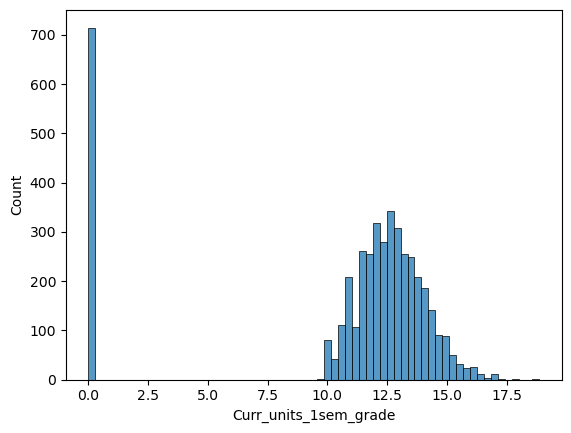

In [13]:
sns.histplot(data=df, x="Curr_units_1sem_grade")

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

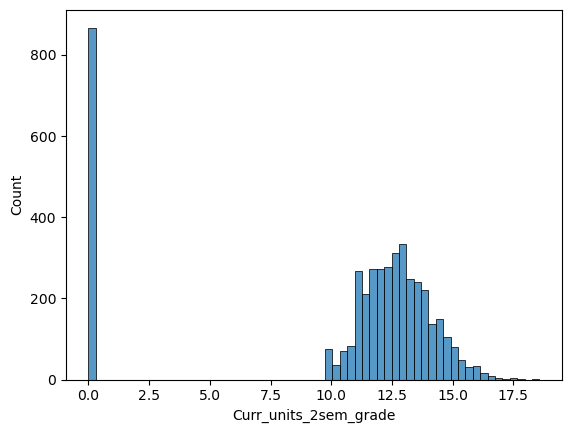

In [14]:
sns.histplot(data=df, x="Curr_units_2sem_grade")

#Se eliminarán todos los 0 dado o es data omisa o alumno que no hizo nada en el curso

In [16]:
#Df selecciona las filas diferentes a O en A/B y las elimina
df1 = df[(df["Curr_units_1sem_grade"] != 0) & (df["Curr_units_2sem_grade"] !=0)]

In [17]:
df1.describe()

,Appl_mode,Appl_order,Course,Day/evening attend,Prev_qualif,Prev_qualif_grade,Mother's_qualif,Father's_qualif,Mother's_occup,Admi_grade,...,Curr_units_1sem_noeval,Curr_units_2sem_cred,Curr_units_2sem_enrol,Curr_units_2sem_eval,Curr_units_2sem_appvd,Curr_units_2sem_grade,Curr_units_2sem_noevaluat,Unemploy_rate,Infl_rate,GDP
count,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,...,3496.000000,3496.000000,3496.00000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000,3496.000000
mean,17.741133,1.764874,9220.362700,0.895881,4.569508,132.649685,19.447654,22.328089,10.812071,127.157580,...,0.110126,0.681922,6.66619,9.061785,5.567792,12.747317,0.117563,11.551201,1.206236,0.063435
std,17.401895,1.343317,1093.916375,0.305459,10.490122,13.053480,15.657497,15.319363,26.818179,13.882074,...,0.569768,2.134015,1.91429,3.163574,2.281099,1.370904,0.584169,2.641430,1.370071,2.266183
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,1.00000,1.000000,1.000000,10.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9119.000000,1.000000,1.000000,124.850000,2.000000,3.000000,4.000000,118.400000,...,0.000000,0.000000,6.00000,7.000000,4.000000,11.750000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9254.000000,1.000000,1.000000,133.000000,19.000000,19.000000,5.000000,126.300000,...,0.000000,0.000000,6.00000,8.000000,6.000000,12.666667,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.500000,...,0.000000,0.000000,8.00000,10.000000,6.000000,13.666667,0.000000,13.900000,2.600000,1.790000
max,53.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,12.000000,19.000000,23.00000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

<Axes: xlabel='Curr_units_1sem_grade', ylabel='Count'>

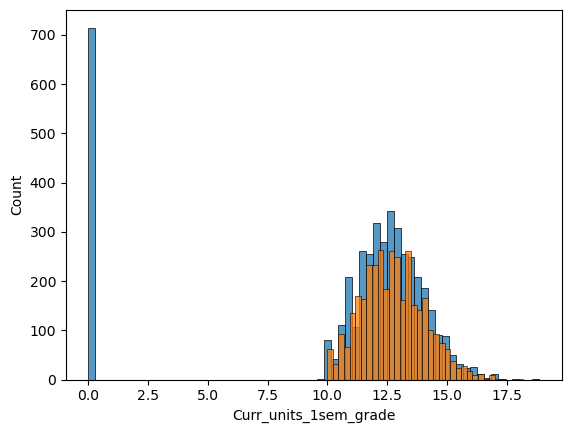

In [18]:
sns.histplot(data=df, x="Curr_units_1sem_grade")
sns.histplot(data=df1, x="Curr_units_1sem_grade")

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

<Axes: xlabel='Curr_units_2sem_grade', ylabel='Count'>

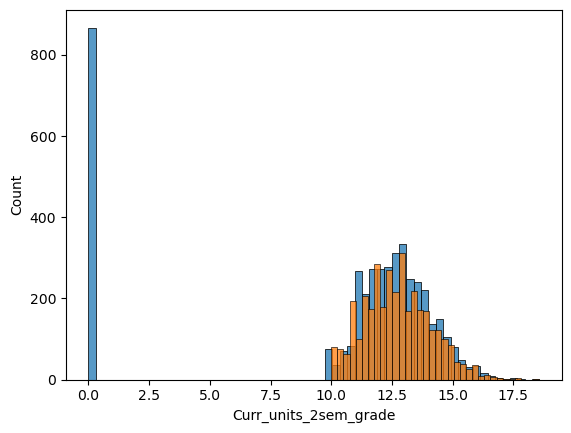

In [19]:
sns.histplot(data=df, x="Curr_units_2sem_grade")
sns.histplot(data=df1, x="Curr_units_2sem_grade")

In [20]:
#Indica los valores unicos de las columnas
columns = ['Curr_units_1sem_cred', 'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
           'Curr_units_1sem_appvd', 
           'Curr_units_1sem_noeval', 'Curr_units_2sem_cred', 'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
           'Curr_units_2sem_appvd', 'Curr_units_2sem_noevaluat']

for i in columns:
    print(f'{i} unique values:' , df1[i].unique())

Curr_units_1sem_cred unique values: <StringArray>
[ '0',  '2',  '3',  '6',  '7', '13',  '4',  '1',  '5', '19', '11',  '8', '10',
  '9', '15', '12', '14', '18', '17', '16', '20', 'Na']
Length: 22, dtype: str
Curr_units_1sem_enrol unique values: [ 6  5  7  8 12 10 18  9 21  3 17 16 11 14 13 15 19  4  2 23 26]
Curr_units_1sem_eval unique values: [ 6  8  9 10  7 14 12 15 13  5 11 17 19 21 18  4 16 24 22  3 45  2 20 26
 29 36 32 23 27 31 28 25 33]
Curr_units_1sem_appvd unique values: [ 6  5  7  4  1  3  2  8 18 10  9 21 11 13 12 16 14 17 19 15 20 26]
Curr_units_1sem_noeval unique values: [ 0  1  2  4  3 12 10  6  7  5]
Curr_units_2sem_cred unique values: [ 0  1  2  5  7  4 10  3 13  9  6 11 12  8 14 15 16 18 19]
Curr_units_2sem_enrol unique values: [ 6.  5.  8.  7. 11. 12.  9. 13. 19.  3. 10. 17.  2.  1. 14.  4. 15. 16.
 23. 18. 21.]
Curr_units_2sem_eval unique values: [ 6 10 17  8  7 14  5  9 12 11 13 19  3 15 16 18  2 21  1 26 27  4 22 20
 24 28 23 25 33]
Curr_units_2sem_appvd unique valu

In [21]:
#Rename columns
df1 = df1.rename(columns={"Marital status": "Marital_status", "Application mode": "Appl_mode", "Application order": "Appl_order", "Daytime/evening attendance": "Day/evening attend", "Previous qualification": "Prev_qualif", "Previous qualification (grade)": "Prev_qualif_grade", "Nacionality": "Nationality", "Mother's qualification": "Mother's_qualif", "Father's qualification": "Father's_qualif", "Mother's occupation": "Mother's_occup", "Father's occupation": "Father's_occup", "Admission grade": "Admi_grade", "Educational special needs": "Educ_special_needs", "Tuition fees up to date": "Tuit_fees_upto_date", "Scholarship holder": "Scholar_holder", "Age at enrollment": "Age_enrollment", "International": "Intl", "Curricular units 1st sem (credited)": "Curr_units_1sem_cred", "Curricular units 1st sem (enrolled)": "Curr_units_1sem_enrol", "Curricular units 1st sem (evaluations)": "Curr_units_1sem_eval", "Curricular units 1st sem (approved)": "Curr_units_1sem_appvd", "Curricular units 1st sem (grade)": "Curr_units_1sem_grade", "Curricular units 1st sem (without evaluations)": "Curr_units_1sem_noeval","Curricular units 2nd sem (credited)": "Curr_units_2sem_cred", "Curricular units 2nd sem (enrolled)": "Curr_units_2sem_enrol", "Curricular units 2nd sem (evaluations)": "Curr_units_2sem_eval", "Curricular units 2nd sem (approved)": "Curr_units_2sem_appvd", "Curricular units 2nd sem (grade)": "Curr_units_2sem_grade", "Curricular units 2nd sem (without evaluations)": "Curr_units_2sem_noevaluat", "Unemployment rate": "Unemploy_rate", "Inflation rate": "Infl_rate"})
df1.columns

Index(['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
       'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
       'Mother's_qualif', 'Father's_qualif', 'Mother's_occup',
       'Father's_occup', 'Admi_grade', 'Displaced', 'Educ_special_needs',
       'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder',
       'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
       'Curr_units_1sem_enrol', 'Curr_units_1sem_eval',
       'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
       'Curr_units_1sem_noeval', 'Curr_units_2sem_cred',
       'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
       'Curr_units_2sem_appvd', 'Curr_units_2sem_grade',
       'Curr_units_2sem_noevaluat', 'Unemploy_rate', 'Infl_rate', 'GDP',
       'Target'],
      dtype='str')

In [22]:
df1["Curr_units_1sem_cred"].unique()

<StringArray>
[ '0',  '2',  '3',  '6',  '7', '13',  '4',  '1',  '5', '19', '11',  '8', '10',
  '9', '15', '12', '14', '18', '17', '16', '20', 'Na']
Length: 22, dtype: str

In [23]:
#Indica los valores unicos de las columnas
columns = ['Marital_status', 'Appl_mode', 'Appl_order', 'Course',
       'Day/evening attend', 'Prev_qualif', 'Prev_qualif_grade', 'Nationality',
       "Mother's_qualif", "Father's_qualif", "Mother's_occup",
       "Father's_occup", 'Admi_grade', 'Displaced', 'Educ_special_needs',
       'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder', 'Unemploy_rate', 'Infl_rate', 'GDP',
       'Target']

for i in columns:
    print(f'{i} unique values:' , df1[i].unique())

Marital_status unique values: <StringArray>
['1', '2', '4', '?', '3', '5', '6']
Length: 7, dtype: str
Appl_mode unique values: [15. 17. 39.  1. 53. 18. 44. 51. 43. 42.  7. 16.  5.  2. 10. 26. 27.]
Appl_order unique values: [1. 2. 3. 4. 6. 5. 9. 0.]
Course unique values: [9254. 9773. 8014. 9991. 9500. 9238. 9670. 9085. 9130. 9853. 9556. 9147.
 9003. 9070. 9119.  171.   33.]
Day/evening attend unique values: [1 0]
Prev_qualif unique values: [ 1 19 42 39 40  4 12  3 43 15  6 38  2  9 10 14]
Prev_qualif_grade unique values: [160.  122.  100.  133.1 142.  137.  138.  139.  136.  110.  149.  135.
 140.  127.  125.  126.  151.  115.  150.  143.  130.  120.  133.  103.
 154.  132.  167.  129.  141.  118.  106.  121.  114.  124.  113.  111.
 123.  131.  158.  117.  153.  178.  116.  134.  128.  148.  155.  145.
 146.  152.  170.  112.  119.  107.  156.   96.  161.  166.  147.  144.
 102.  101.  172.  105.  180.  165.  190.  162.  164.  108.  159.  117.4
 175.  163.  133.8 176.  168.   97.  157.

In [24]:
#0 se convierte en la numerico de la categorica que no tienen respuesta
df1 = df.replace("?", 0)

In [25]:
#'Graduate', 'Dropout', 'Enrolled', 'Grad', 'graduate', 'Drop', 'dropout' se convierte en numeros
df1 = df.replace(['Graduate','Grad', 'graduate'] , 0)
df1 = df.replace(['Dropout', 'Drop', 'dropout'], 1)
df1 = df.replace('Enrolled', 2)

In [26]:
df1["Nationality"].unique()
df1["Tuit_fees_upto_date"].unique()
df1["Marital_status"].unique()

<StringArray>
[  '1',  '62',   '6',  '41',  '26', '103',  '13',  '25',  '21', '101',  '11',
  '22',  '32', '100',  '24', '109',   '2', '108', '105',  '14',   '?',  '17']
Length: 22, dtype: str

<StringArray>
['1', '0', '?']
Length: 3, dtype: str

<StringArray>
['1', '2', '4', '?', '3', '5', '6']
Length: 7, dtype: str

In [27]:
df1 = df.replace("Five", 5)

In [28]:
df1["Father's_occup"].unique()

array(['9', '3', '7', '10', '5', '8', '4', '1', '2', '124', '6', '0',
       '90', '175', '121', '99', '144', '195', '192', '161', '193', '151',
       '182', '132', '131', '194', '163', '135', '143', '171', '103',
       '172', '152', '183', '122', '102', '181', '134', '123', '112',
       '153', '174', '141', '114', 5, '101', '154'], dtype=object)

(array([  6.,  90.,  40., 152., 209., 536., 438., 620., 929., 596., 236.,
        254.,  69., 135.,  29.,  39.,   8.,  14.,   2.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

Text(0, 0.5, 'Frecuencia')

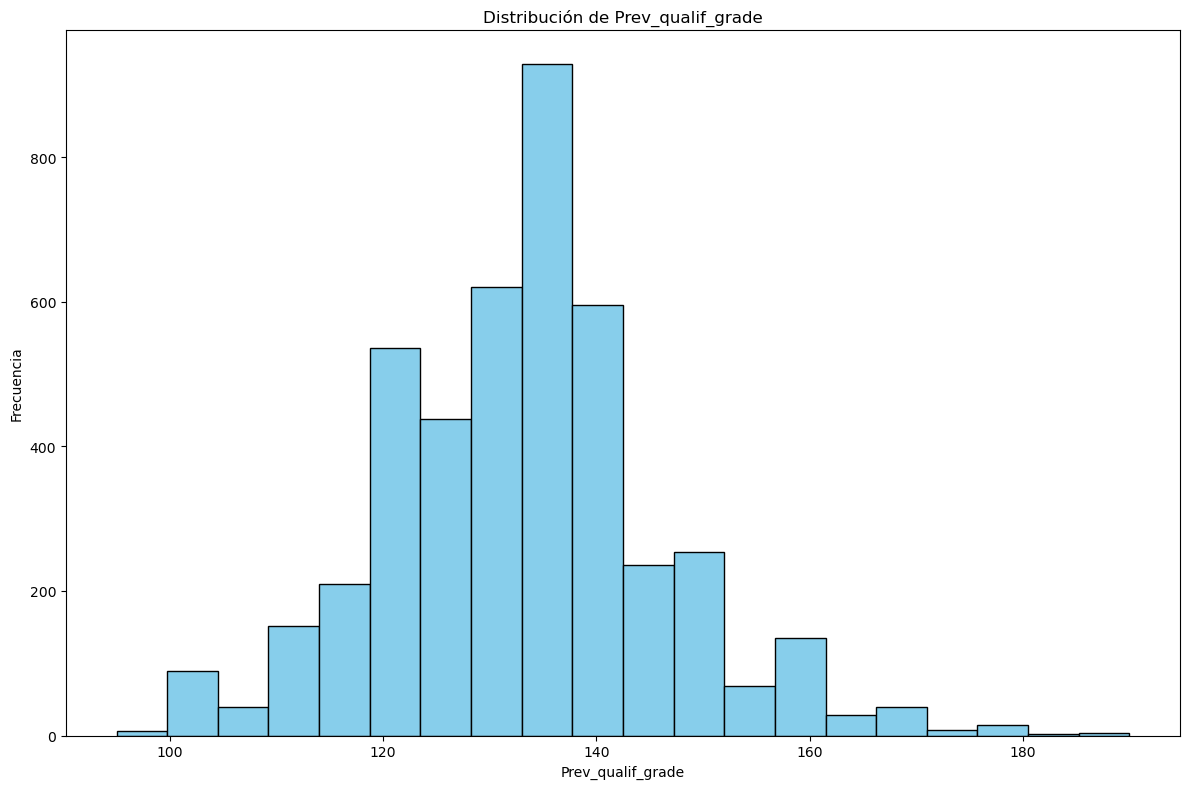

(array([ 50., 190., 151., 335., 472., 697., 620., 620., 350., 352., 139.,
        179.,  94.,  78.,  32.,  24.,   6.,  10.,   3.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Admi_grade')

Text(0.5, 0, 'Admi_grade')

Text(0, 0.5, 'Frecuencia')

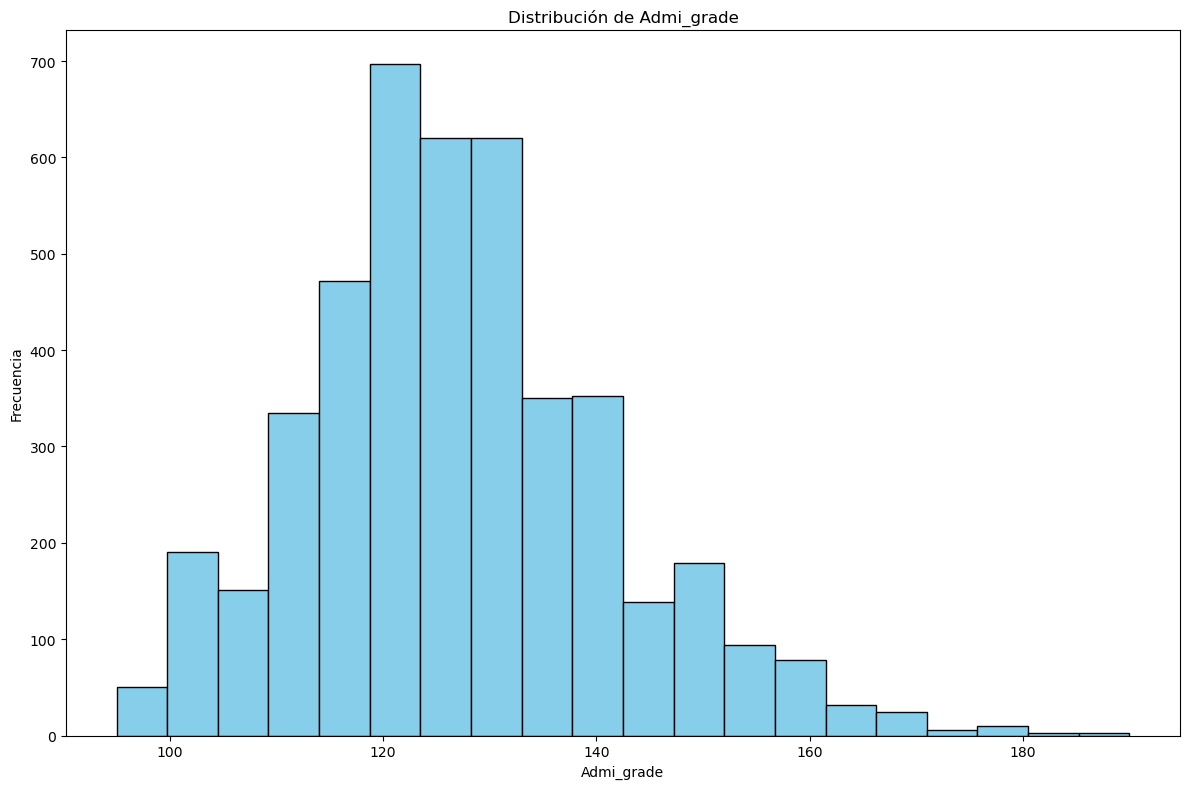

(array([570.,   0.,   0., 365., 527.,   0.,   0., 525., 410.,   0.,   0.,
        861.,   0.,   0., 390.,   0.,   0.,   0., 396., 361.]),
 array([ 7.6 ,  8.03,  8.46,  8.89,  9.32,  9.75, 10.18, 10.61, 11.04,
        11.47, 11.9 , 12.33, 12.76, 13.19, 13.62, 14.05, 14.48, 14.91,
        15.34, 15.77, 16.2 ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Unemploy_rate')

Text(0.5, 0, 'Unemploy_rate')

Text(0, 0.5, 'Frecuencia')

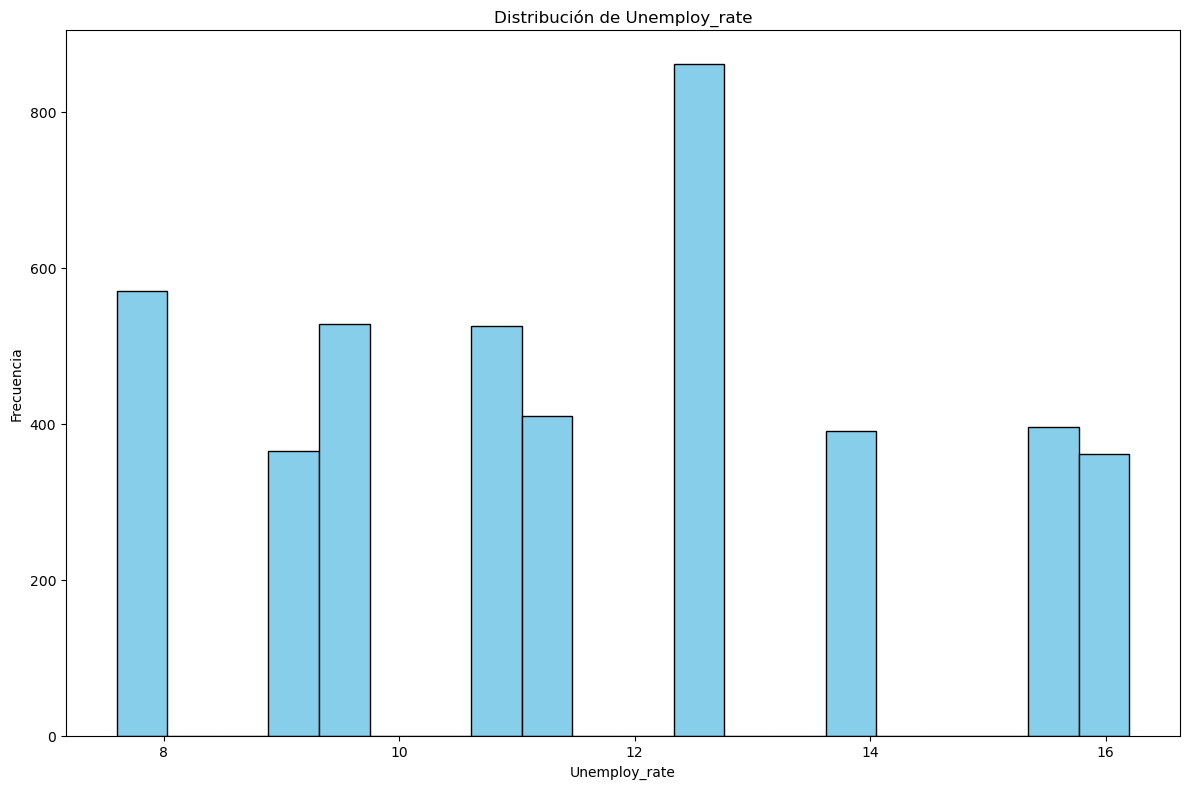

(array([527.,   0., 390.,   0., 361., 444., 410.,   0.,   0., 890.,   0.,
          0.,   0.,   0.,   0., 570., 396.,   0.,   0., 417.]),
 array([-0.8  , -0.575, -0.35 , -0.125,  0.1  ,  0.325,  0.55 ,  0.775,
         1.   ,  1.225,  1.45 ,  1.675,  1.9  ,  2.125,  2.35 ,  2.575,
         2.8  ,  3.025,  3.25 ,  3.475,  3.7  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Infl_rate')

Text(0.5, 0, 'Infl_rate')

Text(0, 0.5, 'Frecuencia')

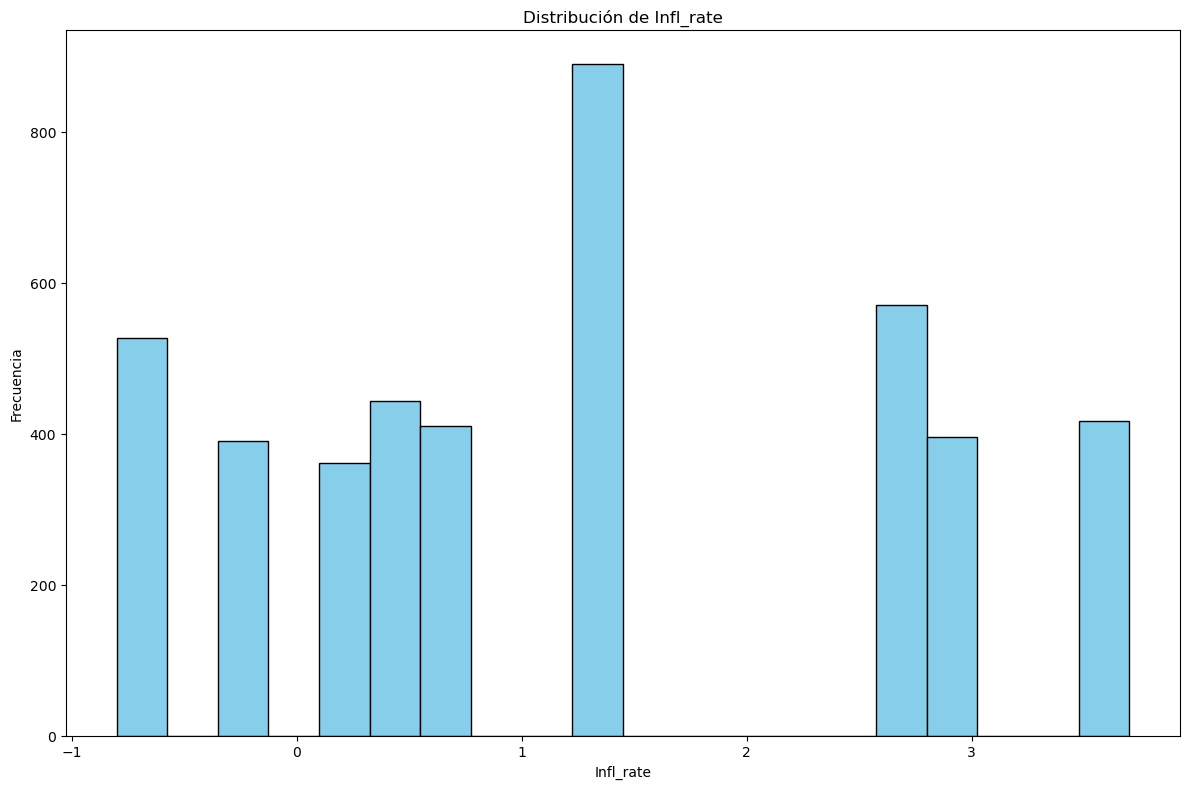

(array([396.,   0., 527.,   0.,   0.,   0., 417.,   0., 361.,   0.,   0.,
        570., 390.,   0.,   0., 969., 410.,   0.,   0., 365.]),
 array([-4.06  , -3.6815, -3.303 , -2.9245, -2.546 , -2.1675, -1.789 ,
        -1.4105, -1.032 , -0.6535, -0.275 ,  0.1035,  0.482 ,  0.8605,
         1.239 ,  1.6175,  1.996 ,  2.3745,  2.753 ,  3.1315,  3.51  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de GDP')

Text(0.5, 0, 'GDP')

Text(0, 0.5, 'Frecuencia')

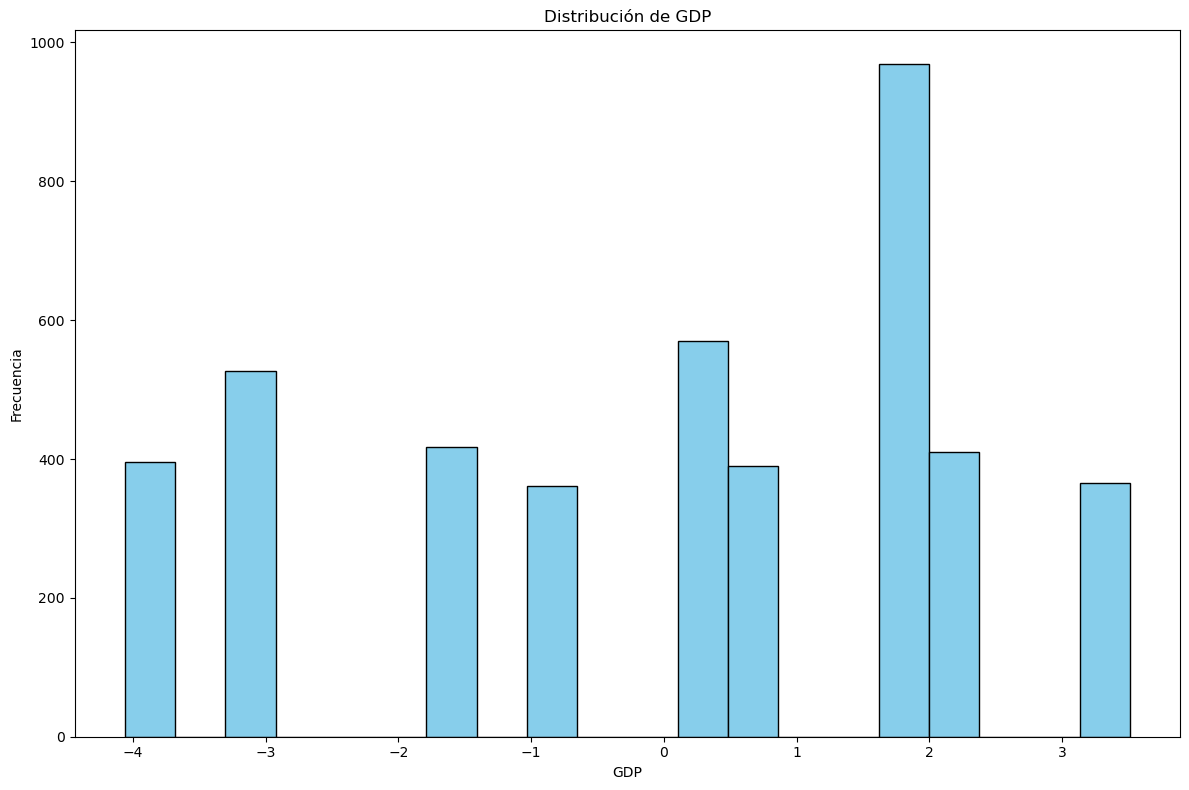

In [29]:
#Continuous columns
cont_col = ['Prev_qualif_grade', 'Admi_grade', 'Unemploy_rate', 'Infl_rate', 'GDP']

df1[cont_col] = df1[cont_col].apply(pd.to_numeric, errors="coerce")

for i in cont_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Graficar histograma
    ax.hist(df[i].dropna(), bins=20, color='skyblue', edgecolor='black')
    
    ax.set_title(f'Distribución de {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frecuencia')
    
    plt.tight_layout()
    plt.show()

(array([3.901e+03, 0.000e+00, 0.000e+00, 3.780e+02, 0.000e+00, 0.000e+00,
        9.100e+01, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 4.000e+00, 0.000e+00, 0.000e+00, 2.400e+01, 0.000e+00,
        0.000e+00, 6.000e+00]),
 array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3. , 3.3, 3.6,
        3.9, 4.2, 4.5, 4.8, 5.1, 5.4, 5.7, 6. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Marital_status')

Text(0.5, 0, 'Marital_status')

Text(0, 0.5, 'Frecuencia')

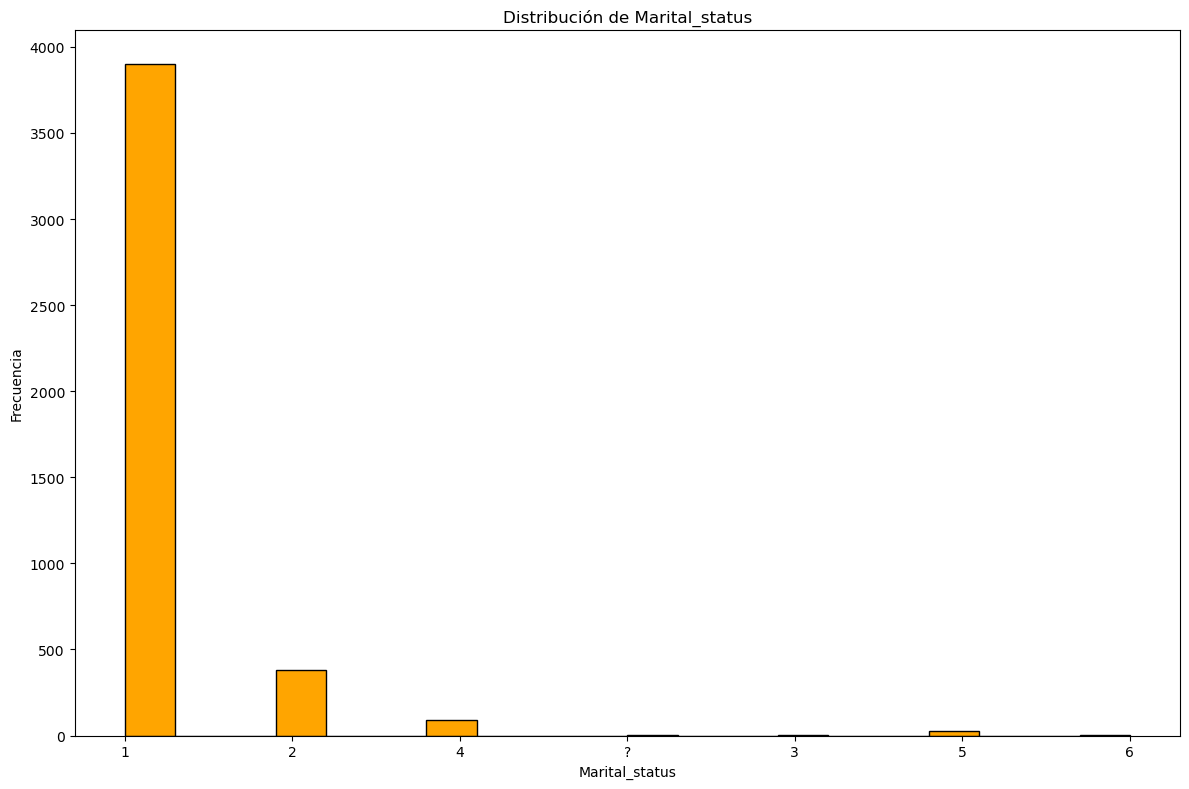

(array([1.699e+03, 1.600e+01, 1.390e+02, 1.000e+01, 0.000e+00, 6.800e+01,
        9.950e+02, 0.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 7.830e+02, 7.700e+01, 5.230e+02, 0.000e+00,
        0.000e+00, 9.300e+01]),
 array([ 1. ,  3.6,  6.2,  8.8, 11.4, 14. , 16.6, 19.2, 21.8, 24.4, 27. ,
        29.6, 32.2, 34.8, 37.4, 40. , 42.6, 45.2, 47.8, 50.4, 53. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Appl_mode')

Text(0.5, 0, 'Appl_mode')

Text(0, 0.5, 'Frecuencia')

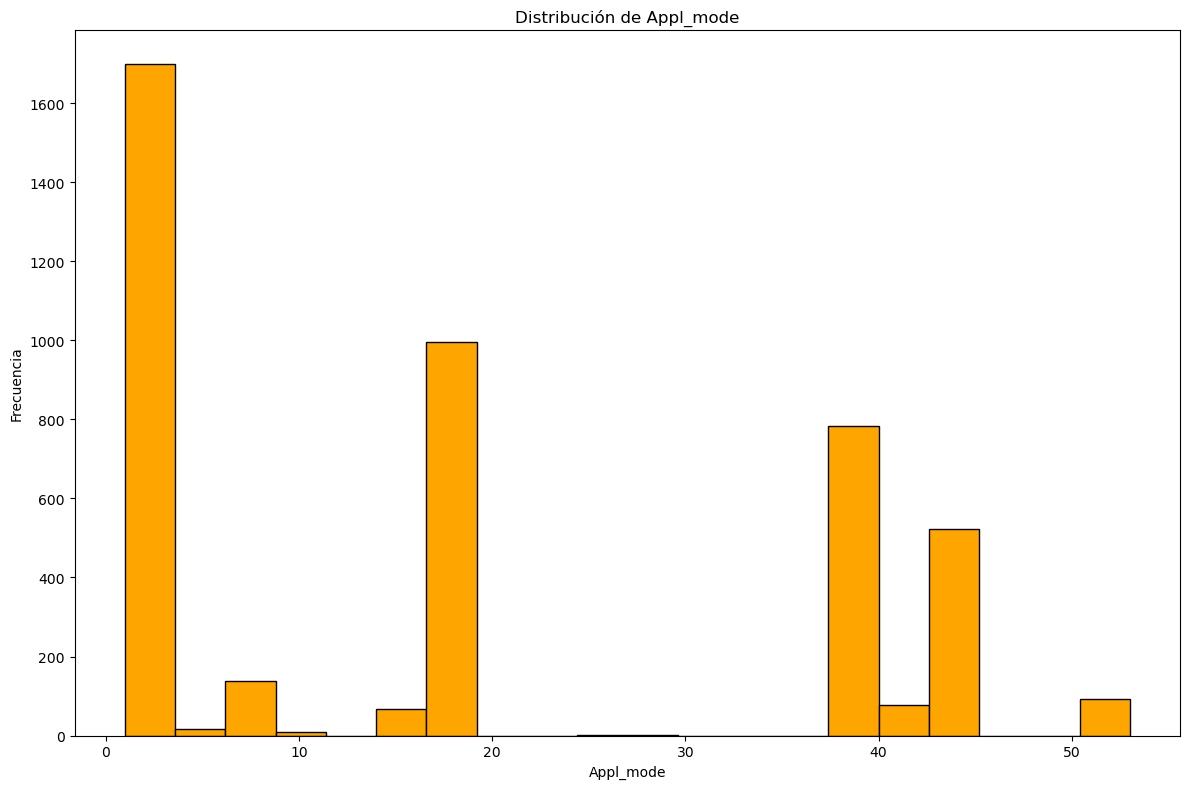

(array([1.000e+00, 0.000e+00, 3.012e+03, 0.000e+00, 5.460e+02, 0.000e+00,
        3.070e+02, 0.000e+00, 2.480e+02, 0.000e+00, 0.000e+00, 1.530e+02,
        0.000e+00, 1.370e+02, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Appl_order')

Text(0.5, 0, 'Appl_order')

Text(0, 0.5, 'Frecuencia')

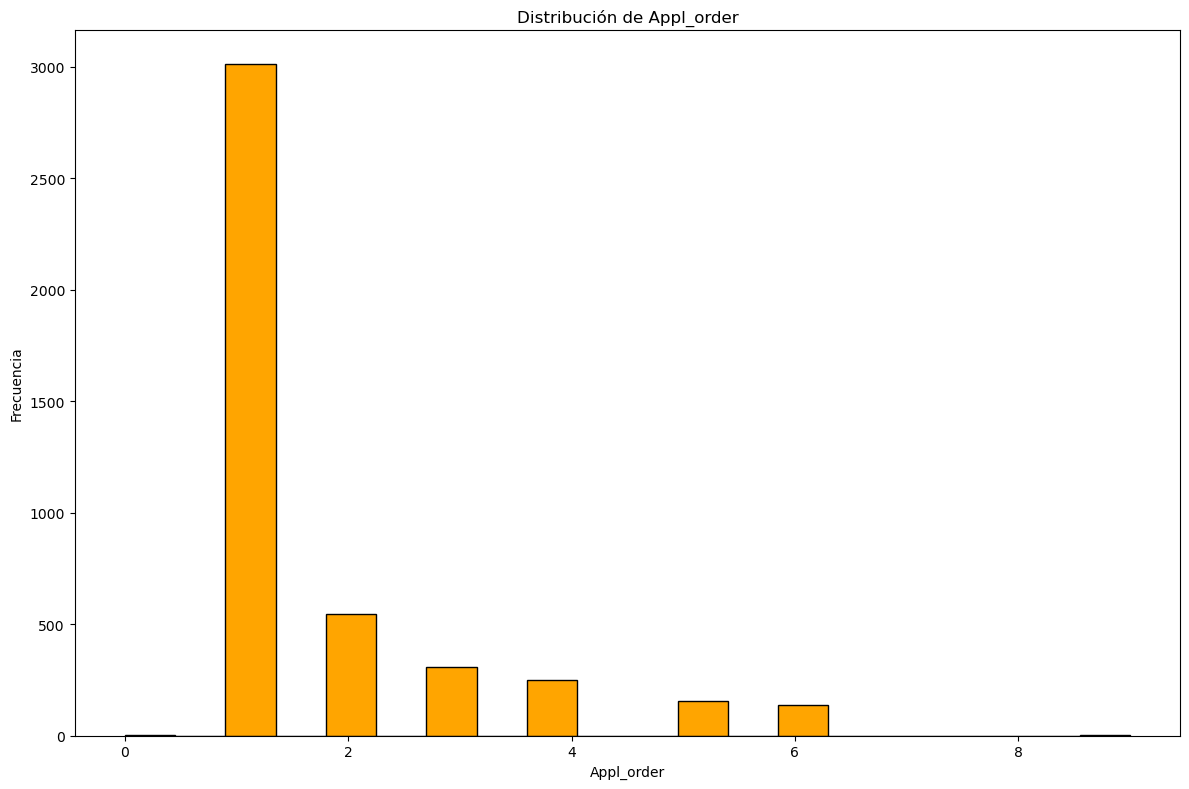

(array([ 225.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,  215.,    0.,
        2059., 1906.]),
 array([  33. ,  530.9, 1028.8, 1526.7, 2024.6, 2522.5, 3020.4, 3518.3,
        4016.2, 4514.1, 5012. , 5509.9, 6007.8, 6505.7, 7003.6, 7501.5,
        7999.4, 8497.3, 8995.2, 9493.1, 9991. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Course')

Text(0.5, 0, 'Course')

Text(0, 0.5, 'Frecuencia')

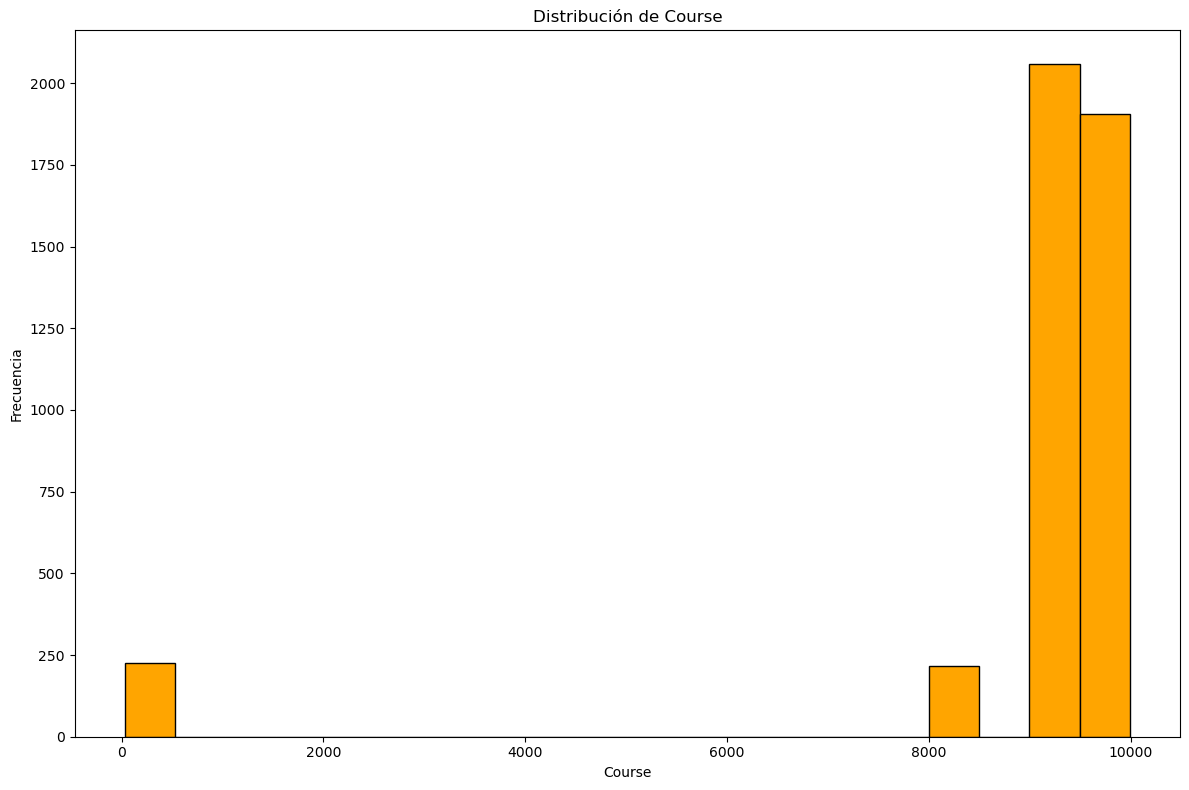

(array([ 482.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 3923.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Day/evening attend')

Text(0.5, 0, 'Day/evening attend')

Text(0, 0.5, 'Frecuencia')

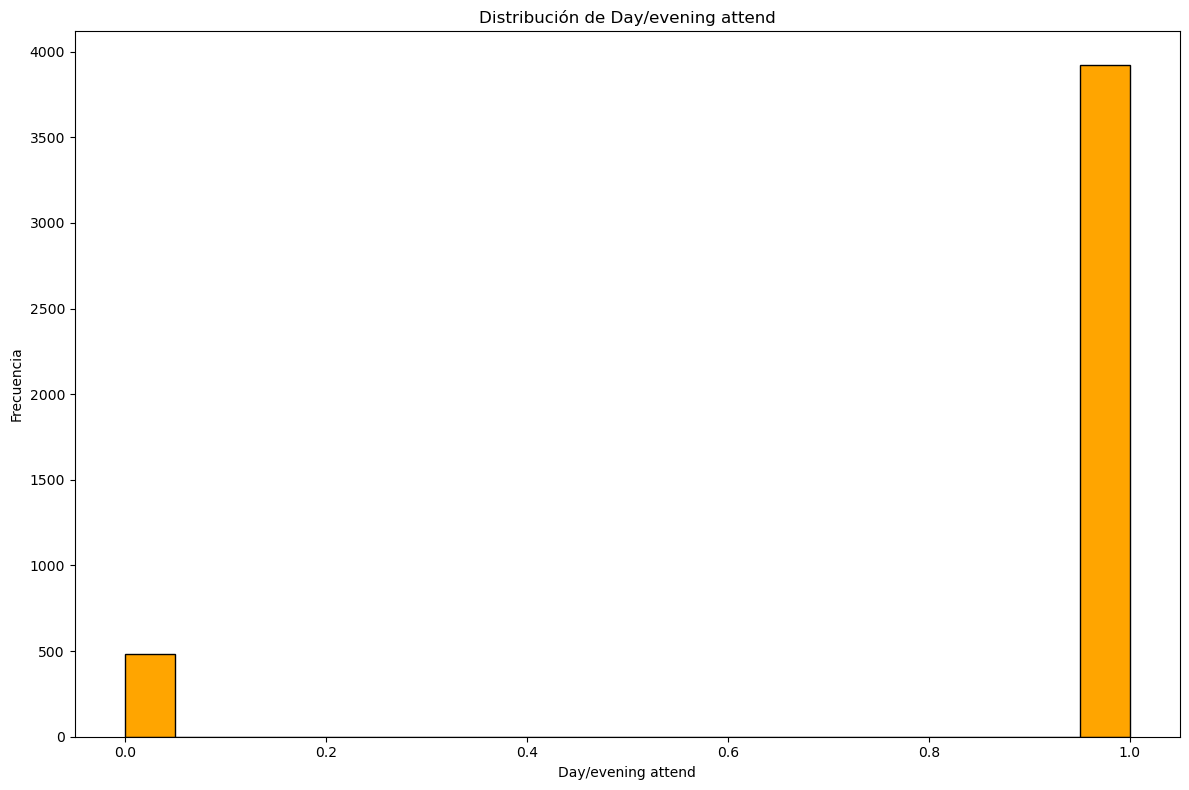

(array([  6.,  90.,  40., 152., 209., 536., 438., 620., 929., 596., 236.,
        254.,  69., 135.,  29.,  39.,   8.,  14.,   2.,   3.]),
 array([ 95.  ,  99.75, 104.5 , 109.25, 114.  , 118.75, 123.5 , 128.25,
        133.  , 137.75, 142.5 , 147.25, 152.  , 156.75, 161.5 , 166.25,
        171.  , 175.75, 180.5 , 185.25, 190.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

Text(0, 0.5, 'Frecuencia')

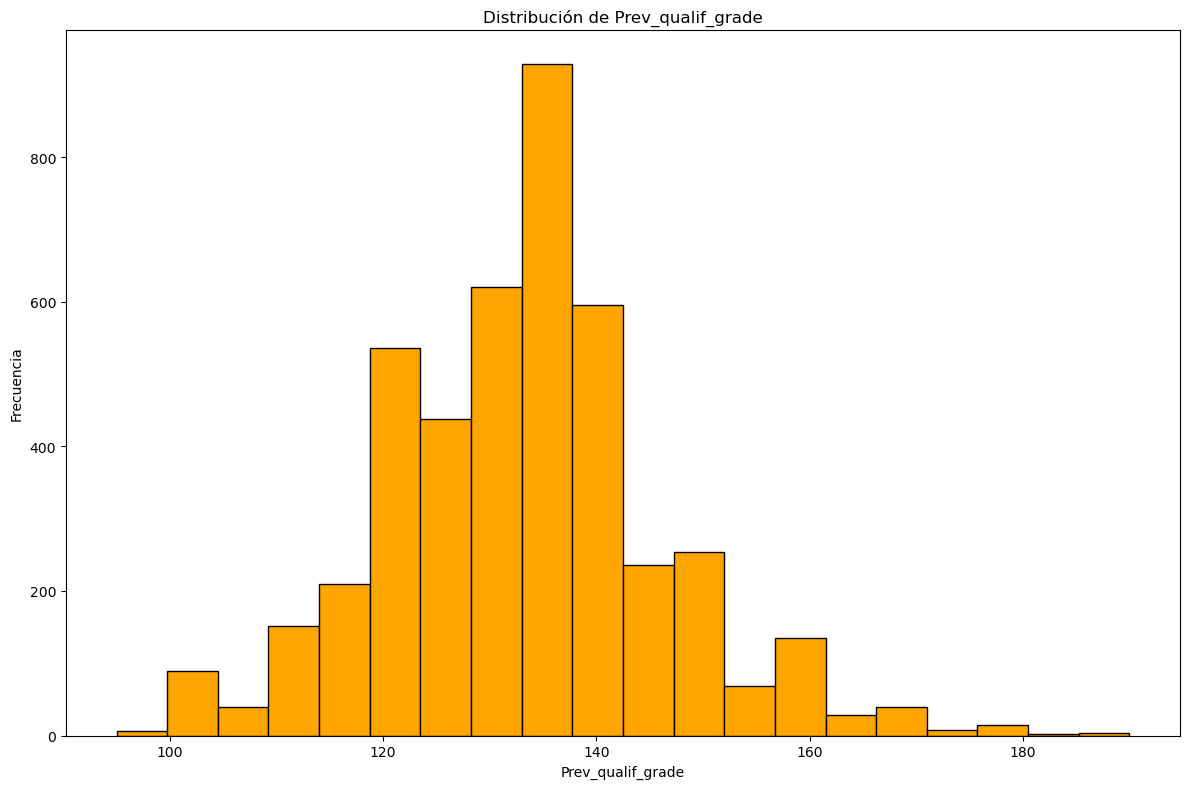

(array([4.297e+03, 1.300e+01, 3.700e+01, 1.400e+01, 3.000e+00, 1.000e+00,
        2.000e+00, 2.000e+00, 2.000e+00, 3.000e+00, 1.300e+01, 1.000e+00,
        3.000e+00, 5.000e+00, 1.000e+00, 2.000e+00, 1.000e+00, 2.000e+00,
        1.000e+00, 2.000e+00]),
 array([ 0.  ,  1.05,  2.1 ,  3.15,  4.2 ,  5.25,  6.3 ,  7.35,  8.4 ,
         9.45, 10.5 , 11.55, 12.6 , 13.65, 14.7 , 15.75, 16.8 , 17.85,
        18.9 , 19.95, 21.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Nationality')

Text(0.5, 0, 'Nationality')

Text(0, 0.5, 'Frecuencia')

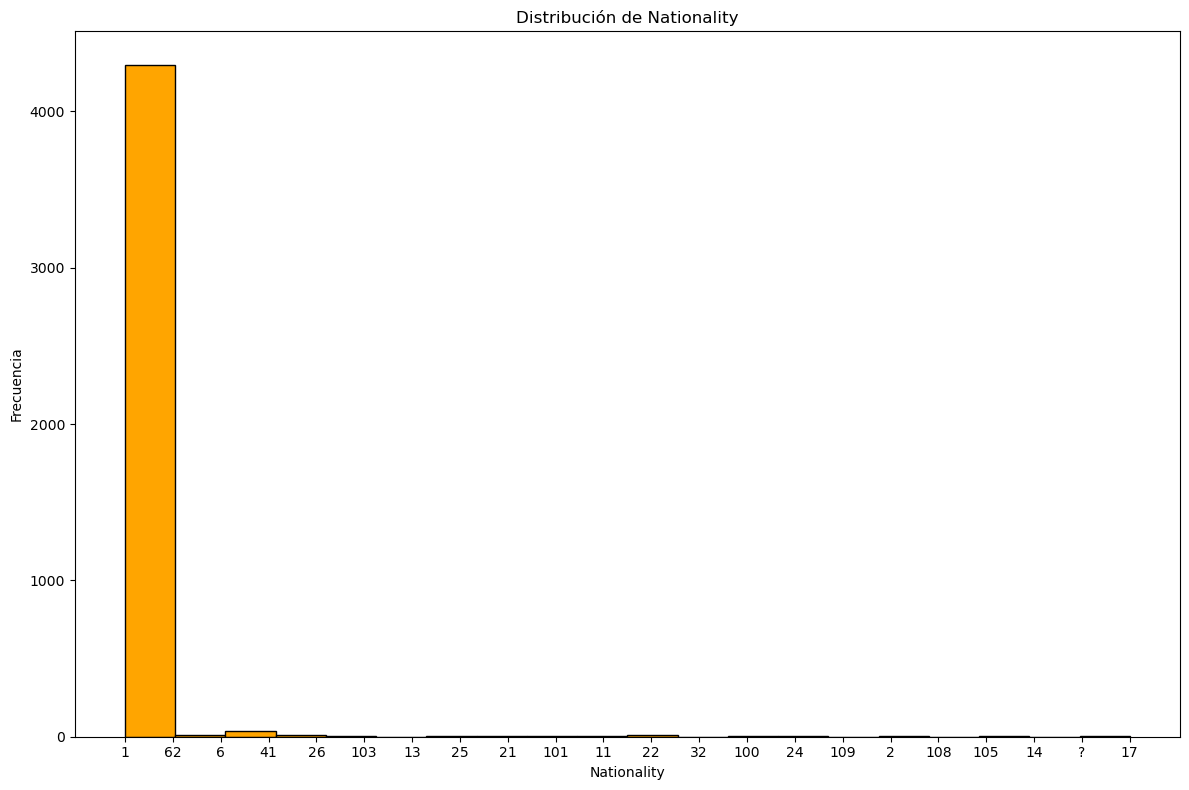

(array([1.581e+03, 6.900e+01, 4.000e+00, 8.000e+00, 6.000e+00, 4.200e+01,
        2.000e+00, 1.000e+00, 9.500e+02, 1.000e+00, 0.000e+00, 1.000e+00,
        1.000e+00, 6.000e+00, 0.000e+00, 1.330e+02, 1.009e+03, 5.670e+02,
        1.500e+01, 9.000e+00]),
 array([ 1.  ,  3.15,  5.3 ,  7.45,  9.6 , 11.75, 13.9 , 16.05, 18.2 ,
        20.35, 22.5 , 24.65, 26.8 , 28.95, 31.1 , 33.25, 35.4 , 37.55,
        39.7 , 41.85, 44.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Mother's_qualif")

Text(0.5, 0, "Mother's_qualif")

Text(0, 0.5, 'Frecuencia')

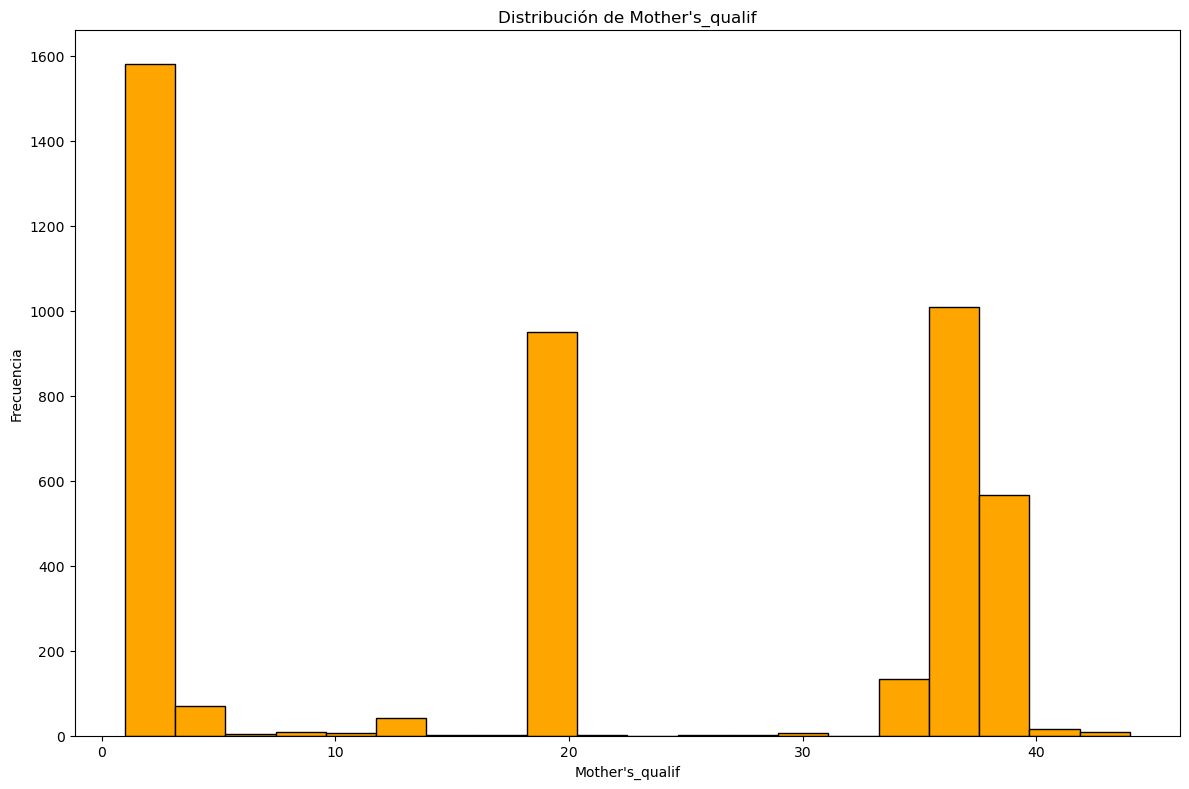

(array([1.247e+03, 5.700e+01, 2.000e+00, 5.000e+00, 1.200e+01, 3.800e+01,
        4.000e+00, 1.000e+00, 9.660e+02, 4.000e+00, 0.000e+00, 3.000e+00,
        1.000e+00, 8.000e+00, 1.000e+00, 1.140e+02, 1.213e+03, 7.180e+02,
        7.000e+00, 4.000e+00]),
 array([ 1.  ,  3.15,  5.3 ,  7.45,  9.6 , 11.75, 13.9 , 16.05, 18.2 ,
        20.35, 22.5 , 24.65, 26.8 , 28.95, 31.1 , 33.25, 35.4 , 37.55,
        39.7 , 41.85, 44.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Father's_qualif")

Text(0.5, 0, "Father's_qualif")

Text(0, 0.5, 'Frecuencia')

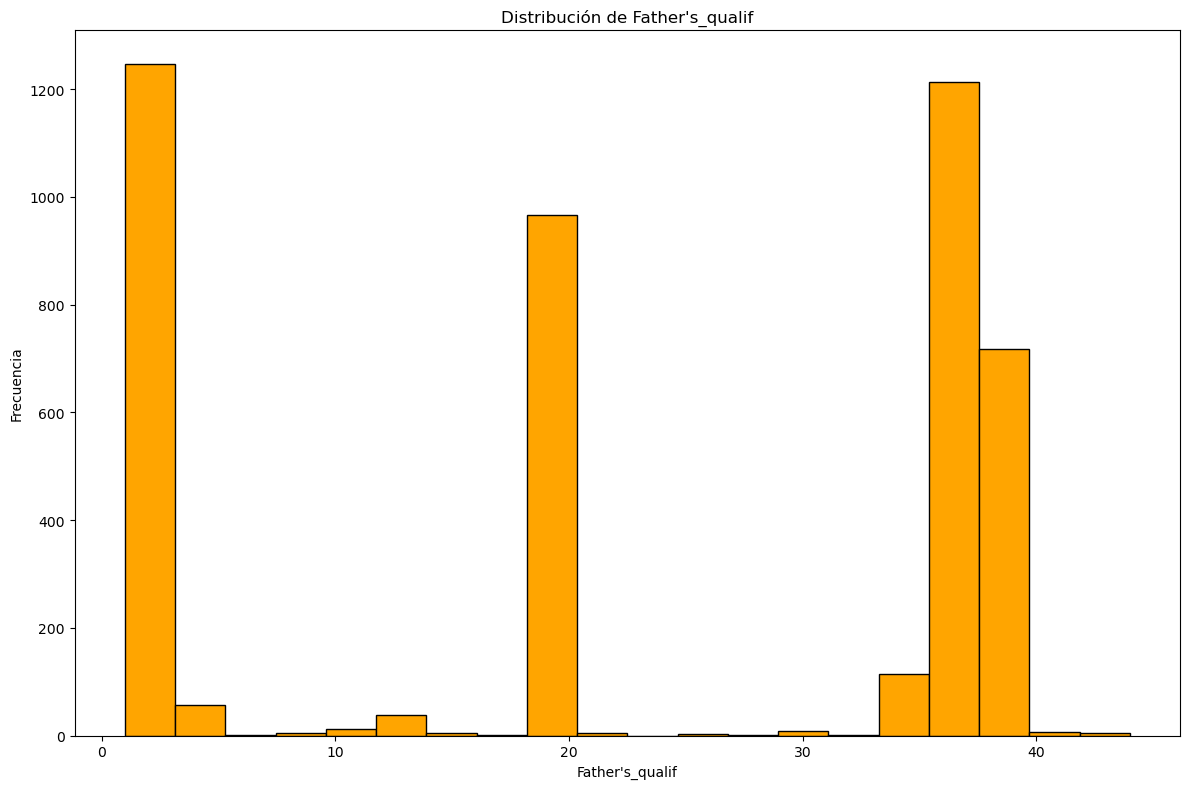

(array([4.219e+03, 4.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 7.000e+01, 1.700e+01, 0.000e+00,
        1.000e+01, 8.000e+00, 1.700e+01, 7.000e+00, 0.000e+00, 2.000e+00,
        5.000e+00, 4.600e+01]),
 array([  0. ,   9.7,  19.4,  29.1,  38.8,  48.5,  58.2,  67.9,  77.6,
         87.3,  97. , 106.7, 116.4, 126.1, 135.8, 145.5, 155.2, 164.9,
        174.6, 184.3, 194. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Mother's_occup")

Text(0.5, 0, "Mother's_occup")

Text(0, 0.5, 'Frecuencia')

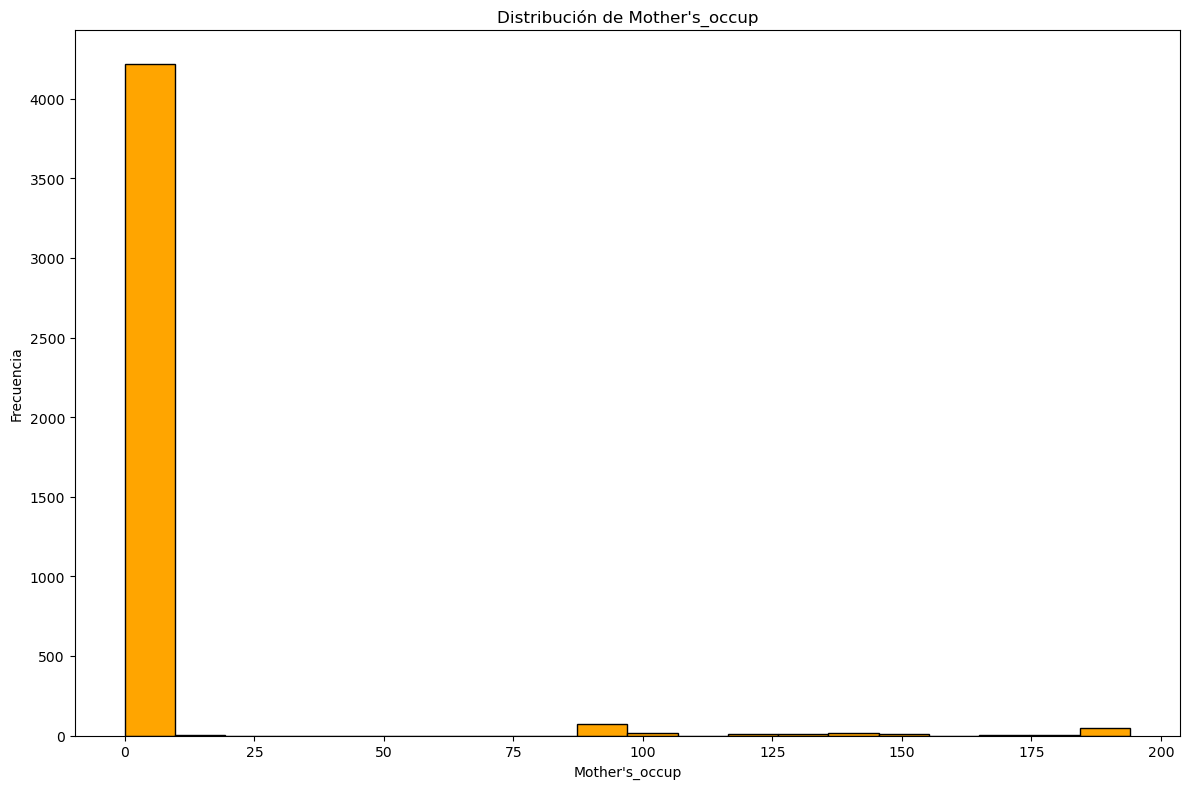

(array([2.054e+03, 7.770e+02, 6.990e+02, 3.290e+02, 3.690e+02, 6.900e+01,
        2.800e+01, 7.000e+00, 1.600e+01, 4.000e+00, 4.000e+00, 8.000e+00,
        9.000e+00, 9.000e+00, 5.000e+00, 5.000e+00, 6.000e+00, 2.000e+00,
        2.000e+00, 3.000e+00]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ,
        25.3, 27.6, 29.9, 32.2, 34.5, 36.8, 39.1, 41.4, 43.7, 46. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, "Distribución de Father's_occup")

Text(0.5, 0, "Father's_occup")

Text(0, 0.5, 'Frecuencia')

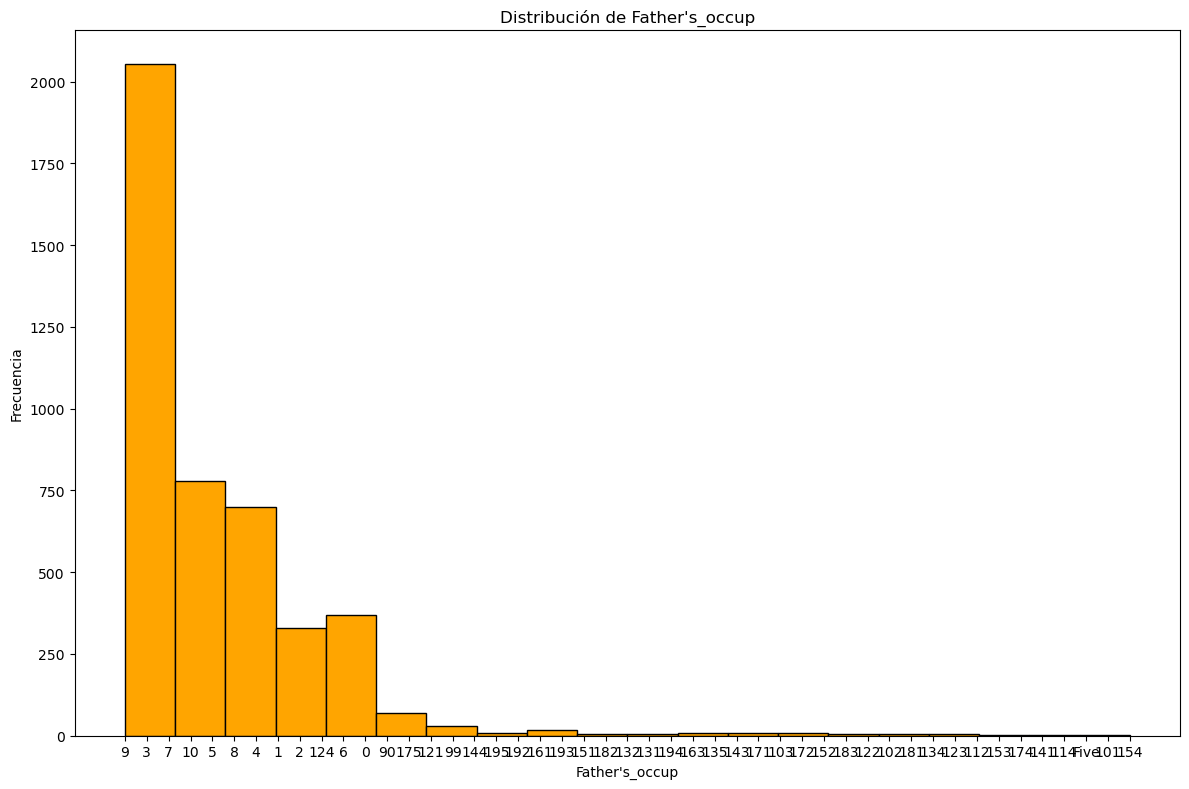

(array([2417.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 1988.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Displaced')

Text(0.5, 0, 'Displaced')

Text(0, 0.5, 'Frecuencia')

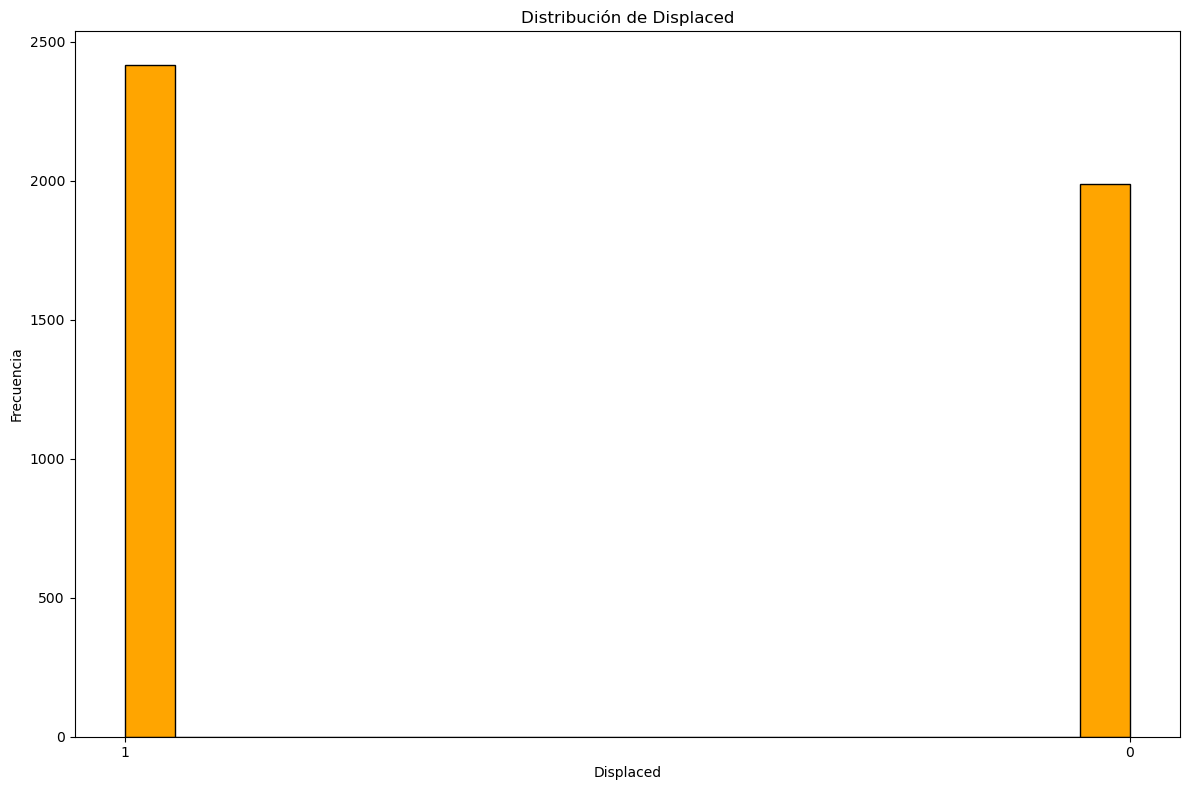

(array([4354.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,   51.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Educ_special_needs')

Text(0.5, 0, 'Educ_special_needs')

Text(0, 0.5, 'Frecuencia')

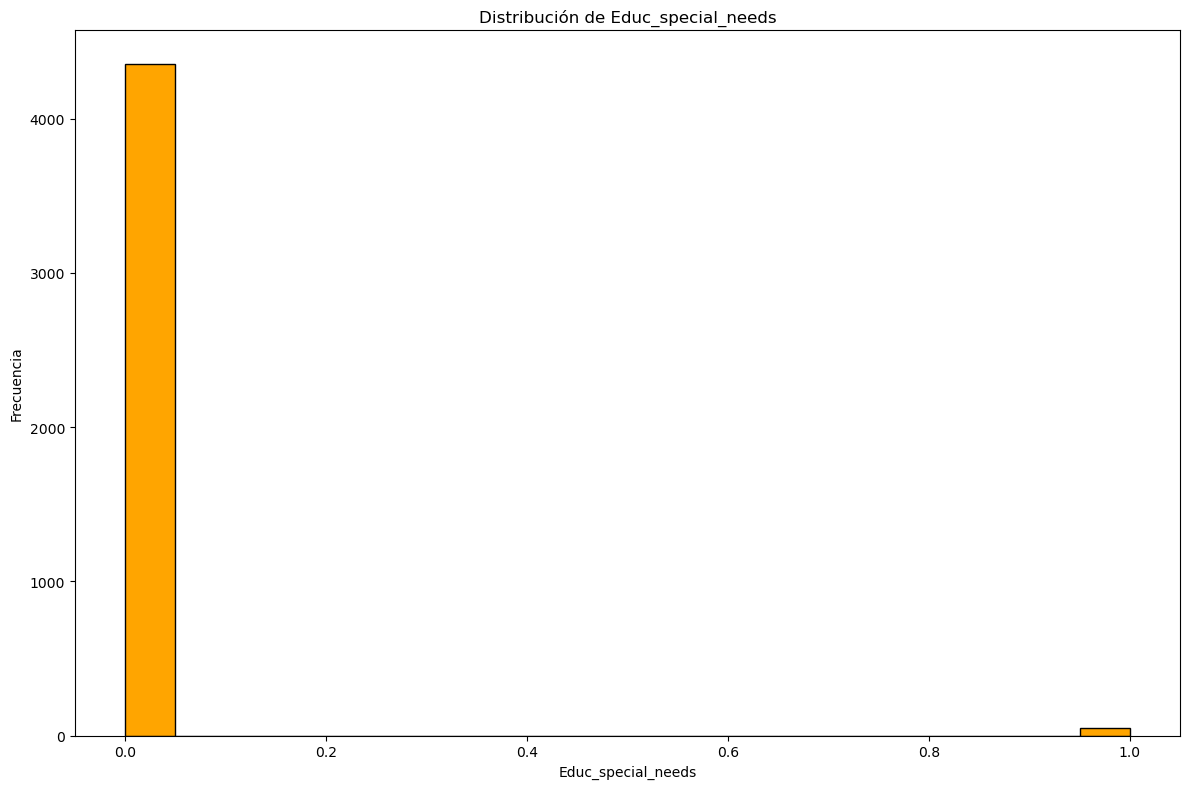

(array([3903.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,  502.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Debtor')

Text(0.5, 0, 'Debtor')

Text(0, 0.5, 'Frecuencia')

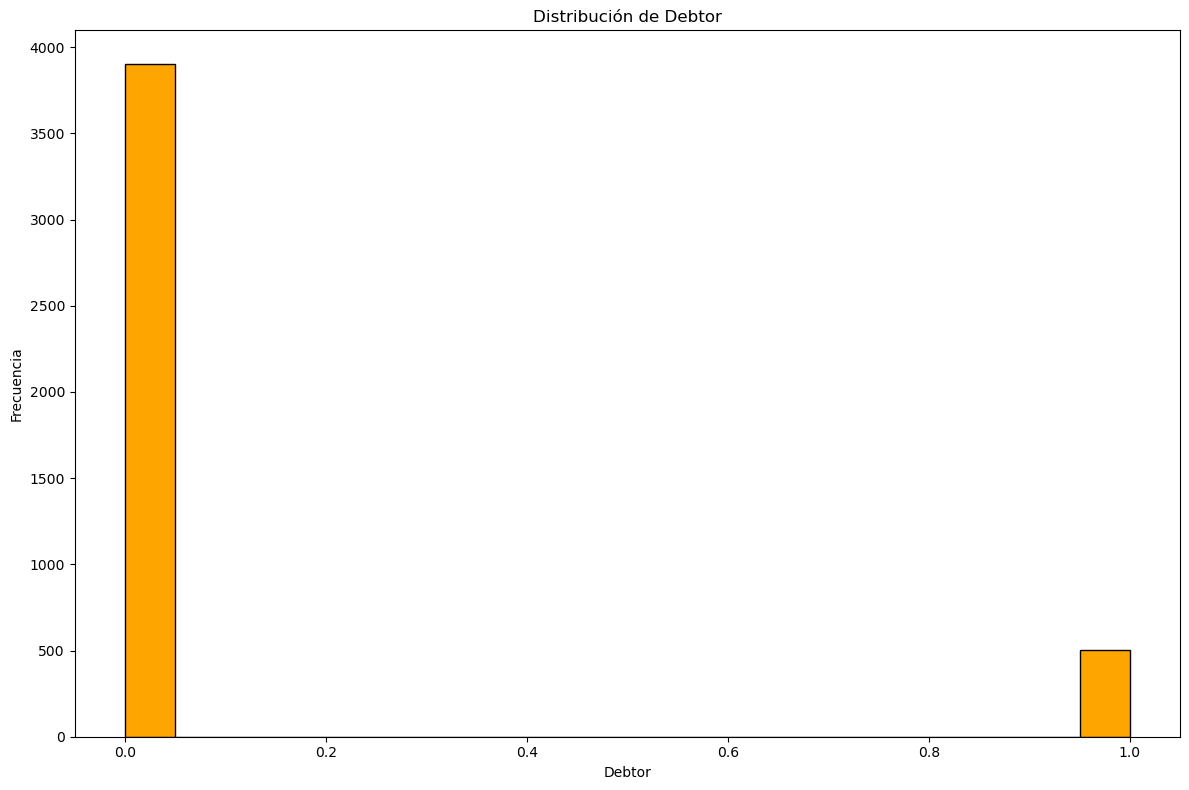

(array([3.878e+03, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 5.260e+02, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Tuit_fees_upto_date')

Text(0.5, 0, 'Tuit_fees_upto_date')

Text(0, 0.5, 'Frecuencia')

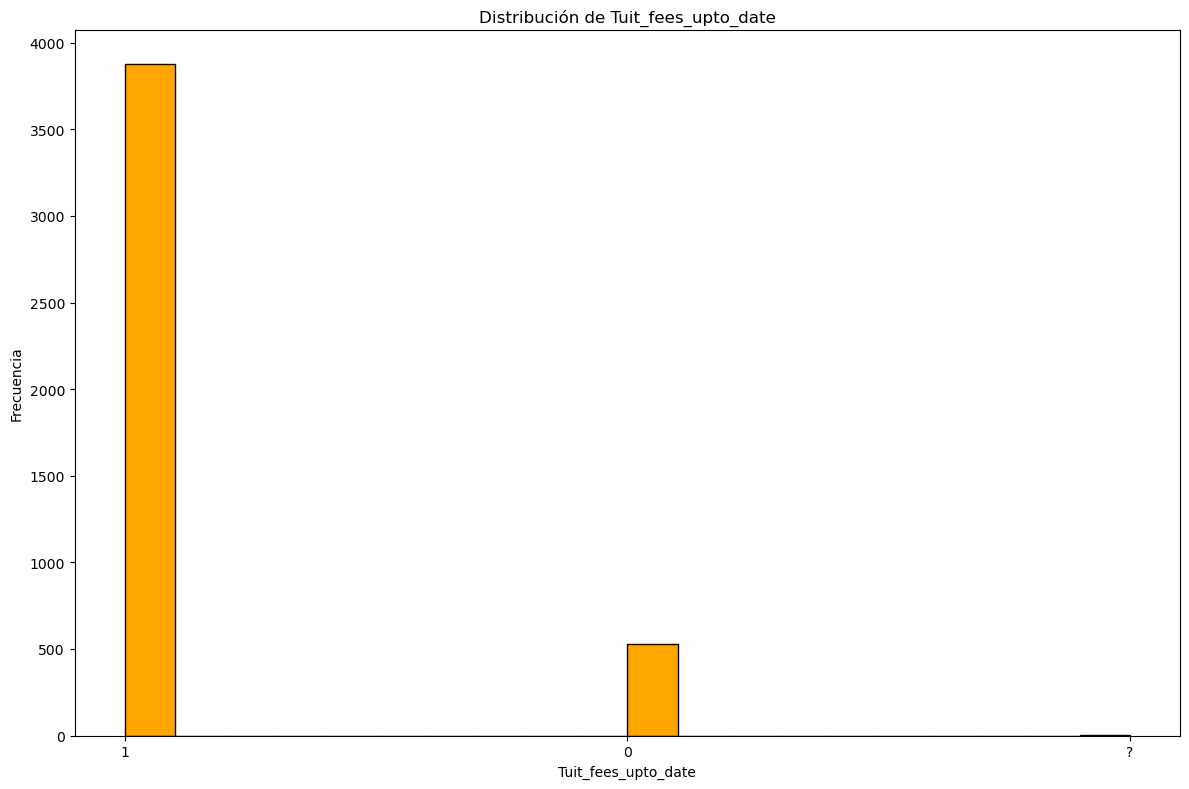

(array([2857.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 1548.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Gender')

Text(0.5, 0, 'Gender')

Text(0, 0.5, 'Frecuencia')

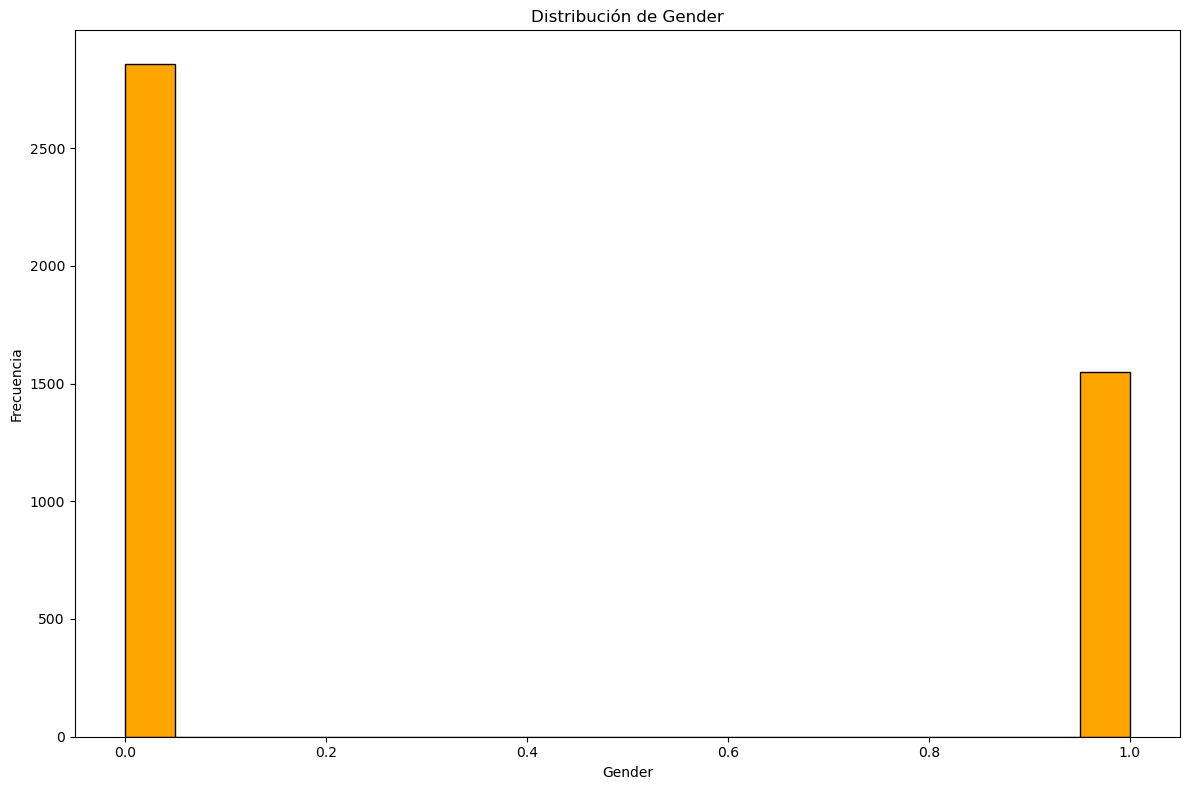

(array([3311.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0., 1094.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Scholar_holder')

Text(0.5, 0, 'Scholar_holder')

Text(0, 0.5, 'Frecuencia')

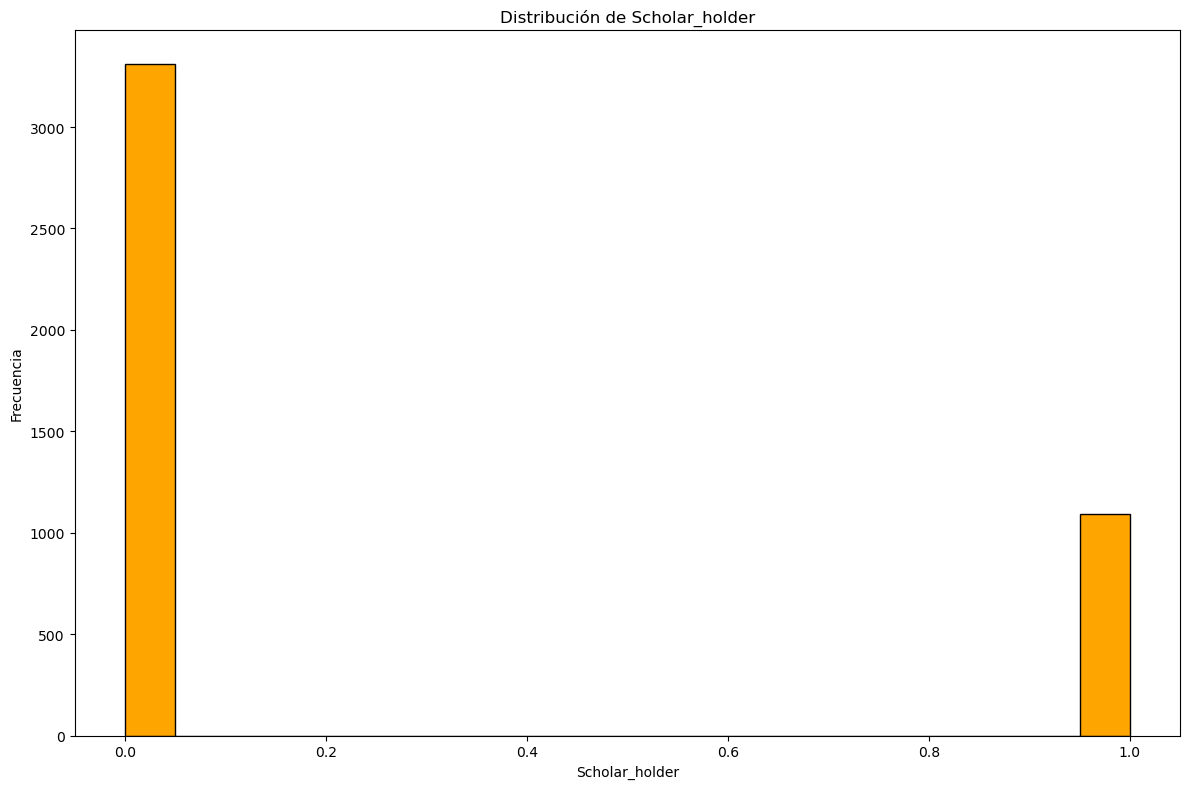

(array([1525., 1048.,  492.,  126.,   43.,  196.,  292.,   94.,  114.,
          53.,  112.,  103.,   84.,   37.,   43.,    3.,   18.,    8.,
           6.,    8.]),
 array([ 0. ,  2.3,  4.6,  6.9,  9.2, 11.5, 13.8, 16.1, 18.4, 20.7, 23. ,
        25.3, 27.6, 29.9, 32.2, 34.5, 36.8, 39.1, 41.4, 43.7, 46. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Age_enrollment')

Text(0.5, 0, 'Age_enrollment')

Text(0, 0.5, 'Frecuencia')

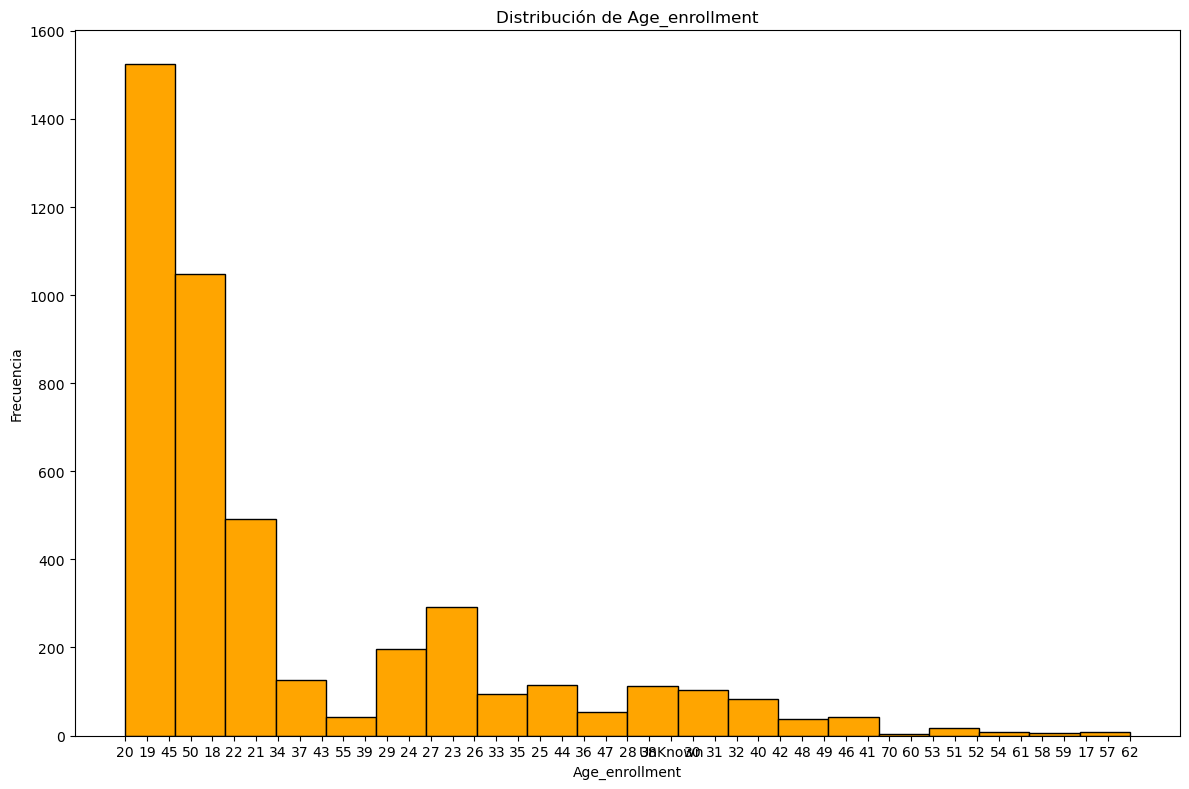

(array([4296.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,  109.]),
 array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
        0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Intl')

Text(0.5, 0, 'Intl')

Text(0, 0.5, 'Frecuencia')

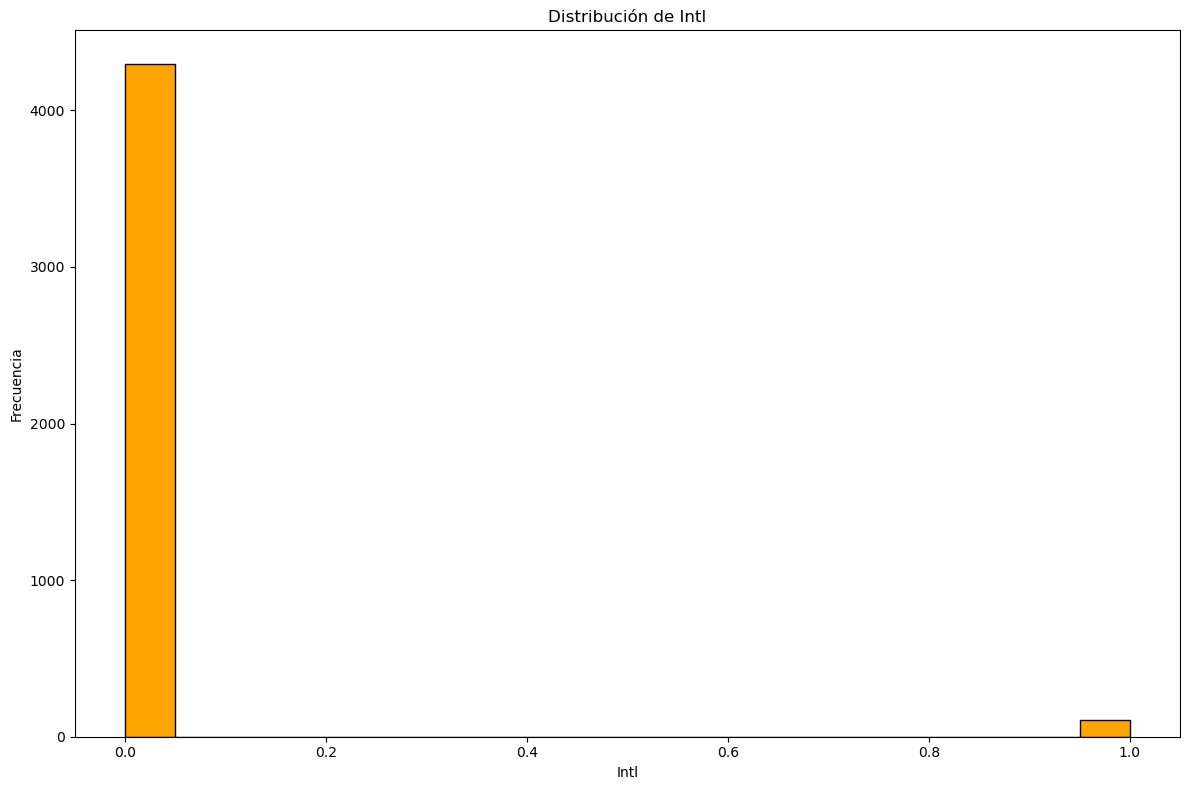

(array([3.923e+03, 6.900e+01, 5.000e+01, 4.100e+01, 1.300e+01, 4.700e+01,
        8.500e+01, 4.000e+01, 2.000e+00, 1.700e+01, 3.100e+01, 1.500e+01,
        2.700e+01, 5.000e+00, 1.200e+01, 1.500e+01, 4.000e+00, 3.000e+00,
        3.000e+00, 3.000e+00]),
 array([ 0.  ,  1.05,  2.1 ,  3.15,  4.2 ,  5.25,  6.3 ,  7.35,  8.4 ,
         9.45, 10.5 , 11.55, 12.6 , 13.65, 14.7 , 15.75, 16.8 , 17.85,
        18.9 , 19.95, 21.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_cred')

Text(0.5, 0, 'Curr_units_1sem_cred')

Text(0, 0.5, 'Frecuencia')

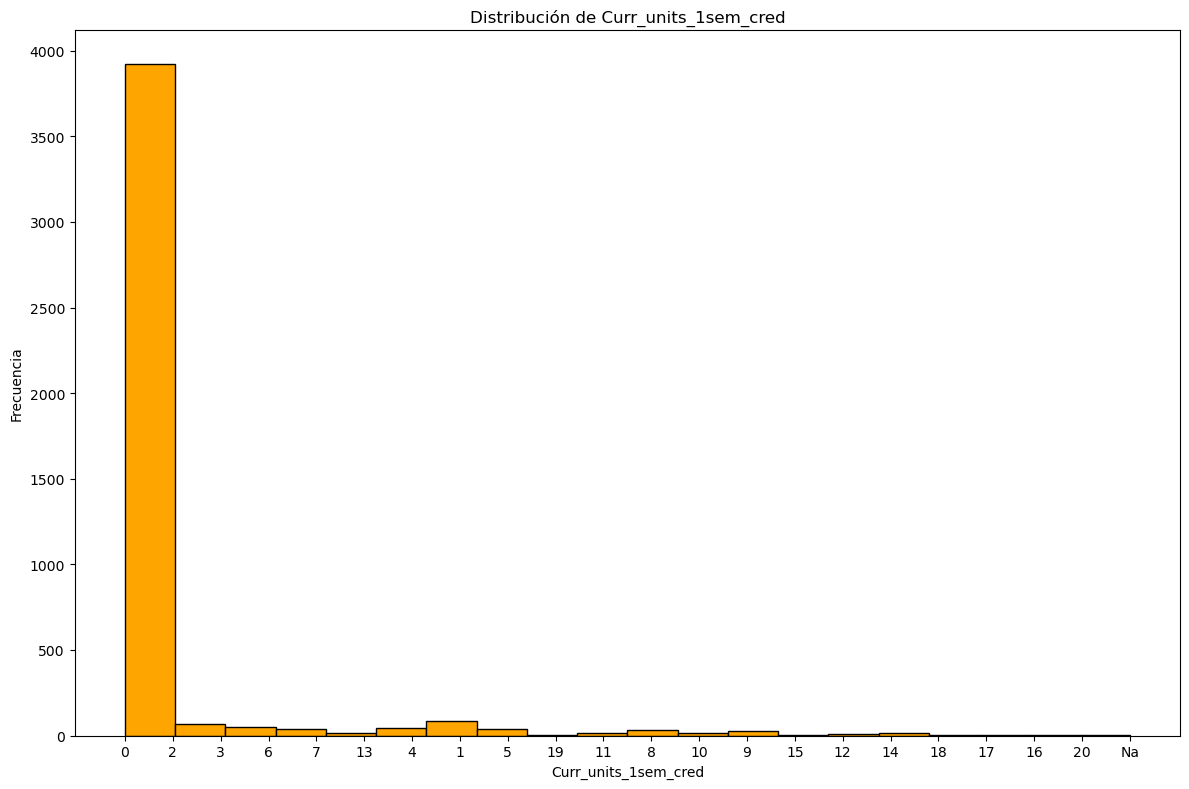

(array([1.850e+02, 9.000e+00, 1.000e+01, 1.026e+03, 1.901e+03, 6.550e+02,
        3.310e+02, 5.100e+01, 4.500e+01, 6.600e+01, 4.200e+01, 2.500e+01,
        1.300e+01, 3.500e+01, 2.000e+00, 0.000e+00, 6.000e+00, 2.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0. ,  1.3,  2.6,  3.9,  5.2,  6.5,  7.8,  9.1, 10.4, 11.7, 13. ,
        14.3, 15.6, 16.9, 18.2, 19.5, 20.8, 22.1, 23.4, 24.7, 26. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_enrol')

Text(0.5, 0, 'Curr_units_1sem_enrol')

Text(0, 0.5, 'Frecuencia')

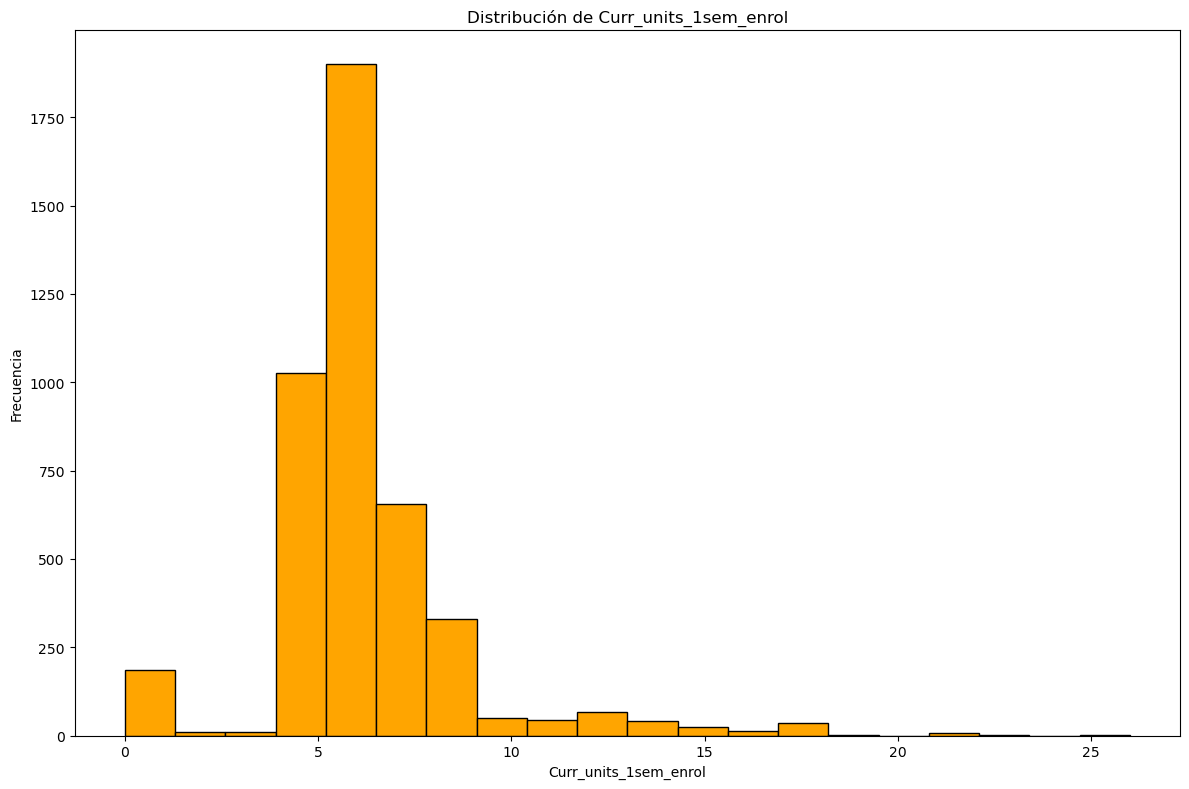

(array([3.610e+02, 2.500e+01, 8.140e+02, 1.486e+03, 9.760e+02, 3.630e+02,
        1.750e+02, 8.000e+01, 6.500e+01, 2.700e+01, 1.500e+01, 7.000e+00,
        5.000e+00, 1.000e+00, 2.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([ 0.  ,  2.25,  4.5 ,  6.75,  9.  , 11.25, 13.5 , 15.75, 18.  ,
        20.25, 22.5 , 24.75, 27.  , 29.25, 31.5 , 33.75, 36.  , 38.25,
        40.5 , 42.75, 45.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_eval')

Text(0.5, 0, 'Curr_units_1sem_eval')

Text(0, 0.5, 'Frecuencia')

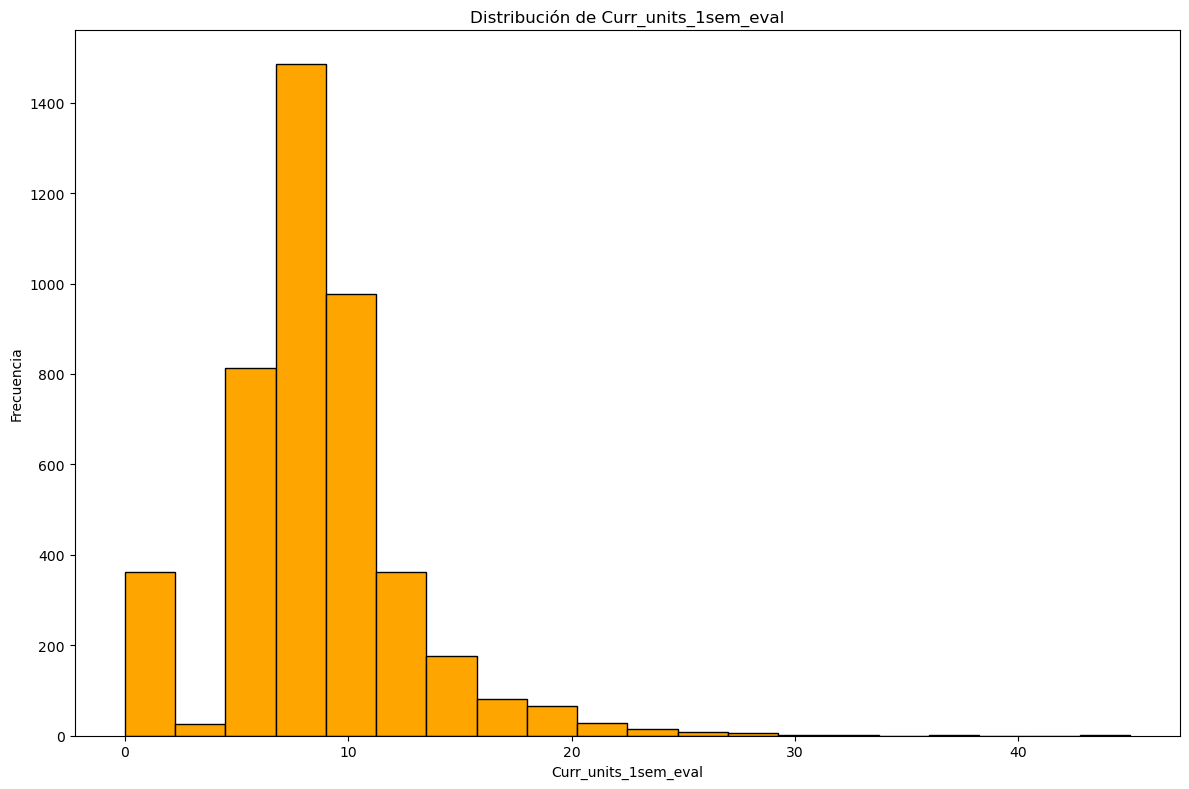

(array([8.410e+02, 1.600e+02, 2.690e+02, 1.149e+03, 1.166e+03, 4.690e+02,
        1.470e+02, 2.400e+01, 4.900e+01, 4.400e+01, 4.000e+01, 7.000e+00,
        5.000e+00, 2.500e+01, 2.000e+00, 3.000e+00, 4.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0. ,  1.3,  2.6,  3.9,  5.2,  6.5,  7.8,  9.1, 10.4, 11.7, 13. ,
        14.3, 15.6, 16.9, 18.2, 19.5, 20.8, 22.1, 23.4, 24.7, 26. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_appvd')

Text(0.5, 0, 'Curr_units_1sem_appvd')

Text(0, 0.5, 'Frecuencia')

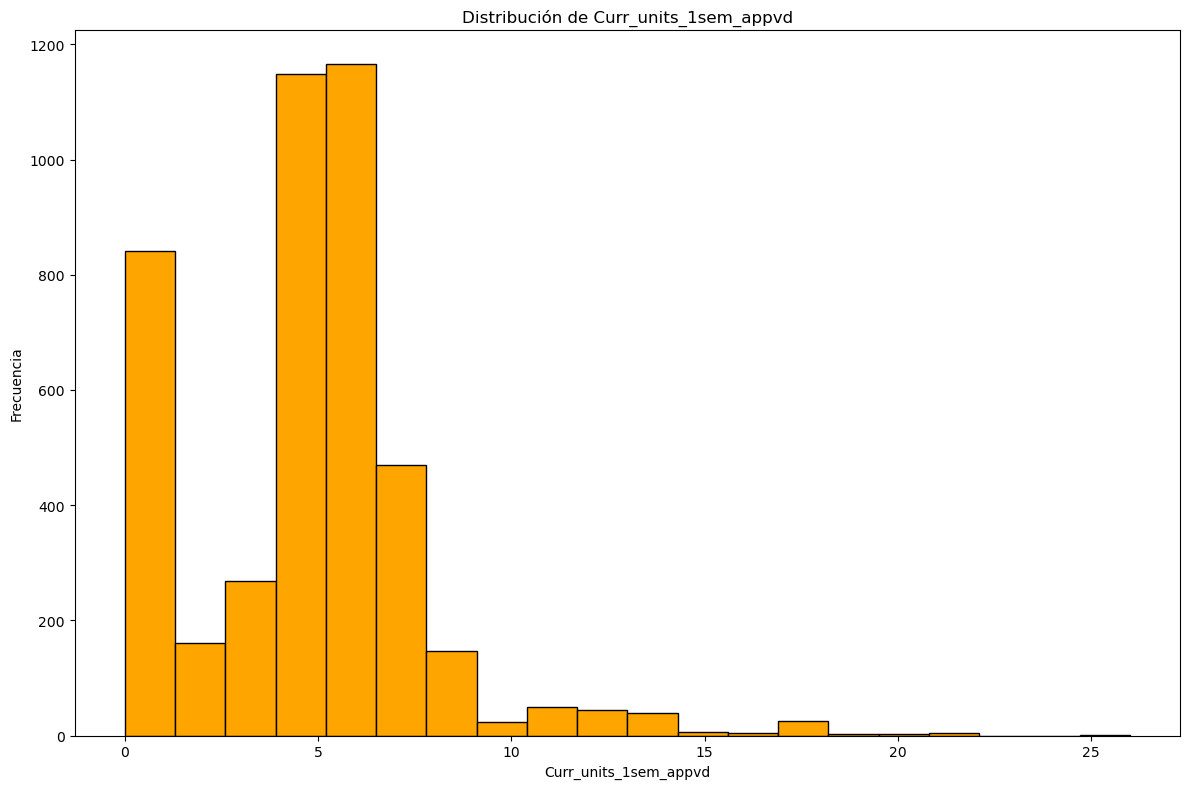

(array([715.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 119.,
        428., 924., 958., 733., 368., 119.,  28.,  10.,   3.]),
 array([ 0.     ,  0.94375,  1.8875 ,  2.83125,  3.775  ,  4.71875,
         5.6625 ,  6.60625,  7.55   ,  8.49375,  9.4375 , 10.38125,
        11.325  , 12.26875, 13.2125 , 14.15625, 15.1    , 16.04375,
        16.9875 , 17.93125, 18.875  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_grade')

Text(0.5, 0, 'Curr_units_1sem_grade')

Text(0, 0.5, 'Frecuencia')

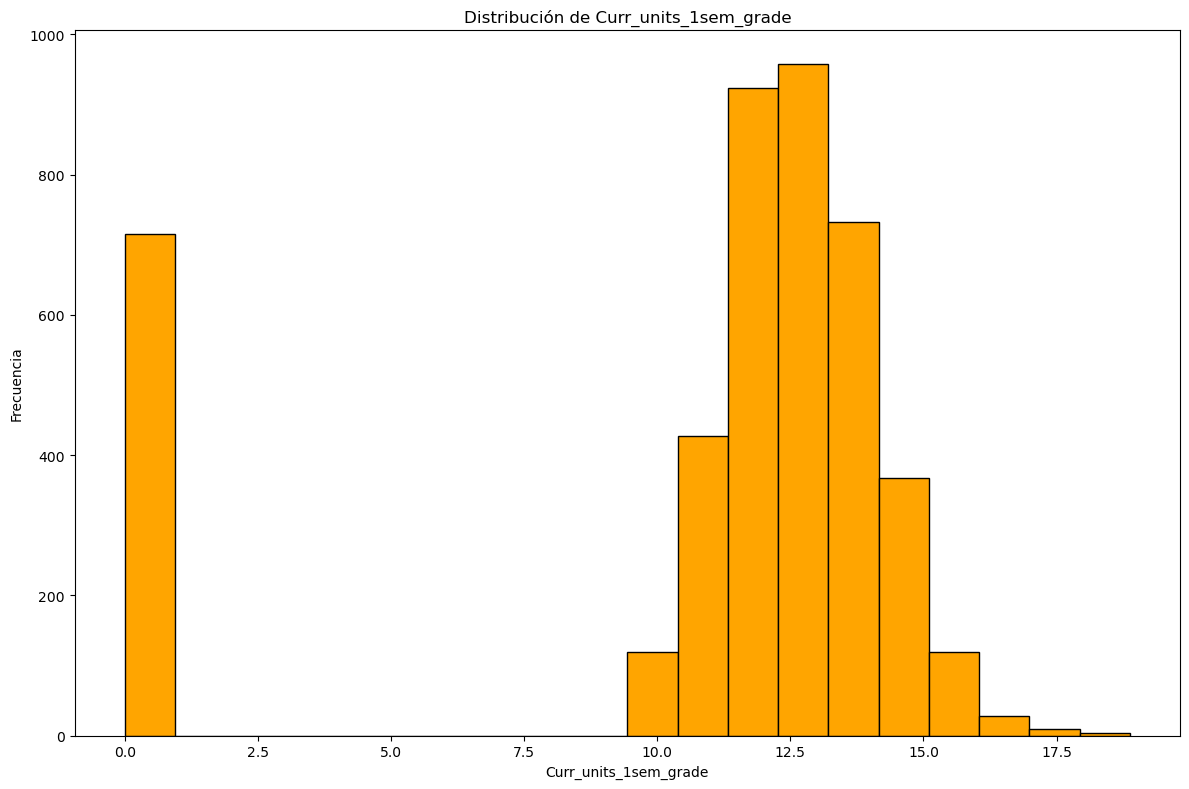

(array([4.113e+03, 1.520e+02, 0.000e+00, 7.800e+01, 0.000e+00, 2.300e+01,
        1.500e+01, 0.000e+00, 5.000e+00, 0.000e+00, 6.000e+00, 6.000e+00,
        0.000e+00, 4.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([ 0. ,  0.6,  1.2,  1.8,  2.4,  3. ,  3.6,  4.2,  4.8,  5.4,  6. ,
         6.6,  7.2,  7.8,  8.4,  9. ,  9.6, 10.2, 10.8, 11.4, 12. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_1sem_noeval')

Text(0.5, 0, 'Curr_units_1sem_noeval')

Text(0, 0.5, 'Frecuencia')

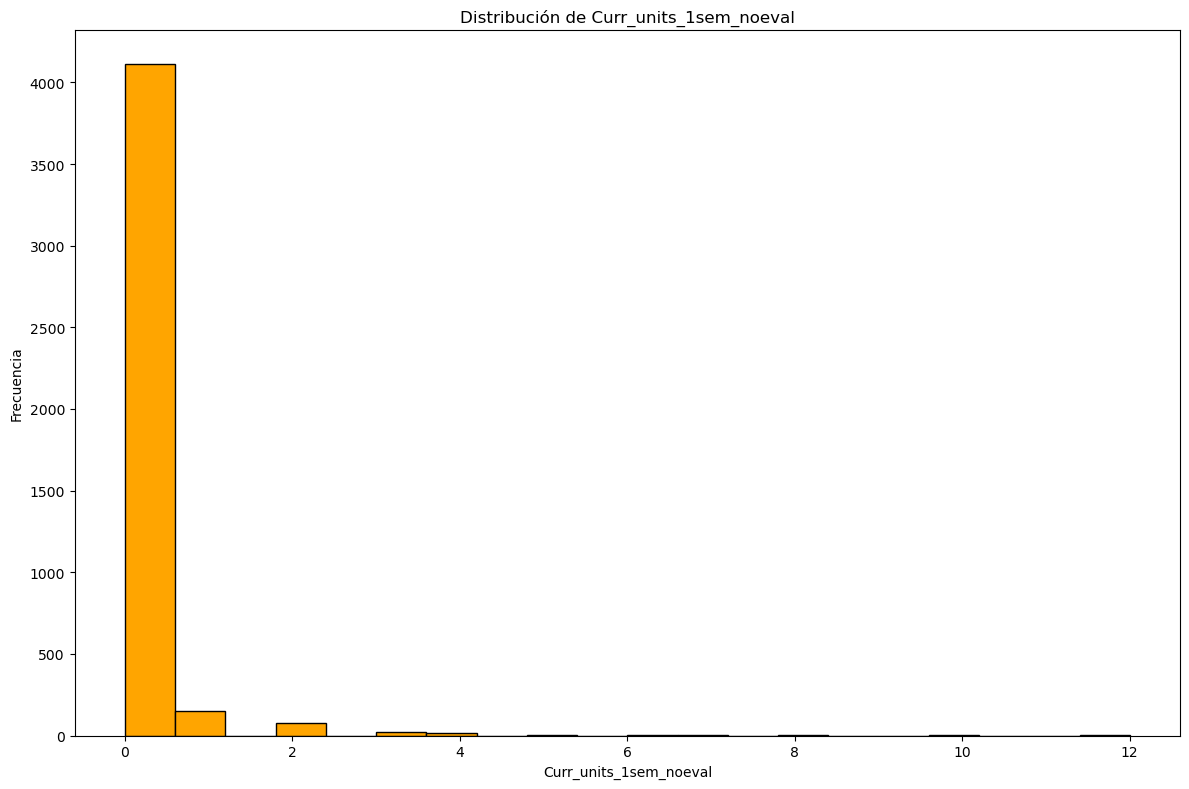

(array([3.877e+03, 1.060e+02, 9.200e+01, 4.900e+01, 7.800e+01, 6.700e+01,
        2.600e+01, 1.600e+01, 1.200e+01, 1.500e+01, 1.300e+01, 2.000e+01,
        1.400e+01, 9.000e+00, 4.000e+00, 2.000e+00, 2.000e+00, 0.000e+00,
        2.000e+00, 1.000e+00]),
 array([ 0.  ,  0.95,  1.9 ,  2.85,  3.8 ,  4.75,  5.7 ,  6.65,  7.6 ,
         8.55,  9.5 , 10.45, 11.4 , 12.35, 13.3 , 14.25, 15.2 , 16.15,
        17.1 , 18.05, 19.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_cred')

Text(0.5, 0, 'Curr_units_2sem_cred')

Text(0, 0.5, 'Frecuencia')

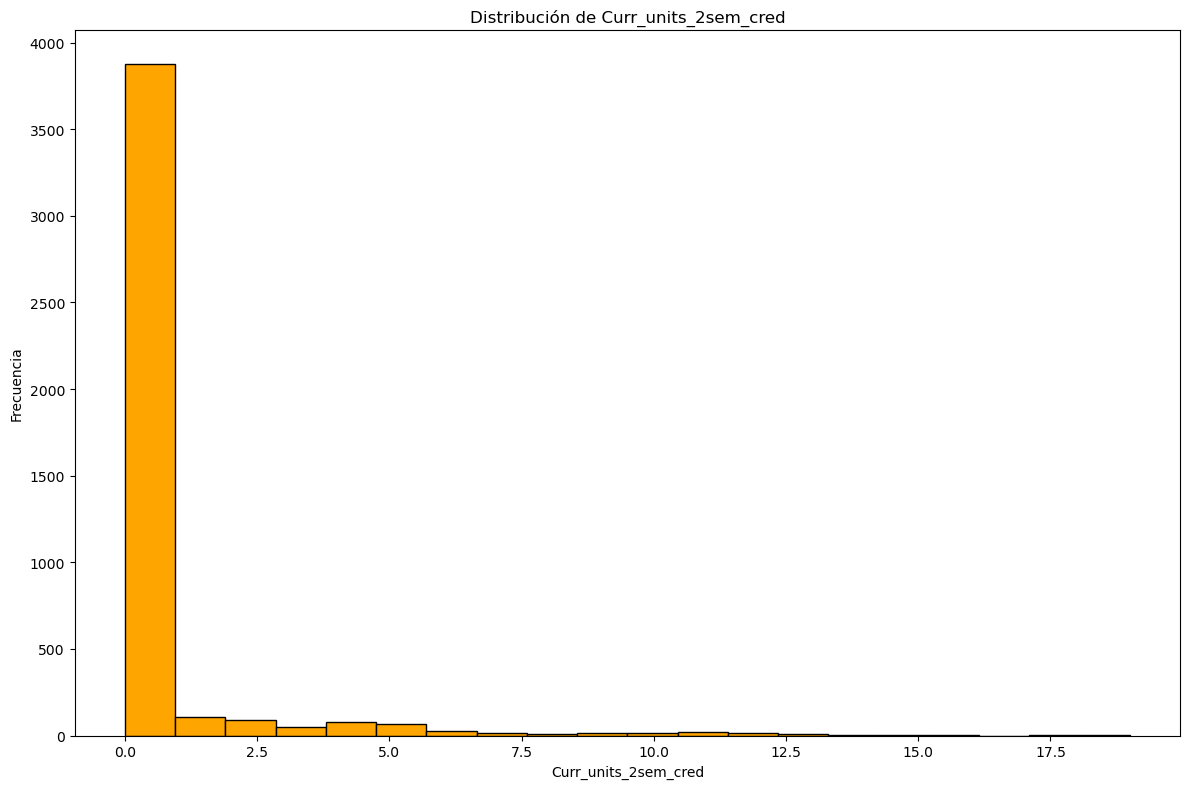

(array([1.810e+02, 5.000e+00, 3.000e+00, 1.700e+01, 1.049e+03, 1.904e+03,
        9.630e+02, 5.000e+01, 4.700e+01, 6.000e+01, 4.400e+01, 3.700e+01,
        2.200e+01, 3.000e+00, 1.200e+01, 2.000e+00, 3.000e+00, 0.000e+00,
        1.000e+00, 2.000e+00]),
 array([ 0.  ,  1.15,  2.3 ,  3.45,  4.6 ,  5.75,  6.9 ,  8.05,  9.2 ,
        10.35, 11.5 , 12.65, 13.8 , 14.95, 16.1 , 17.25, 18.4 , 19.55,
        20.7 , 21.85, 23.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_enrol')

Text(0.5, 0, 'Curr_units_2sem_enrol')

Text(0, 0.5, 'Frecuencia')

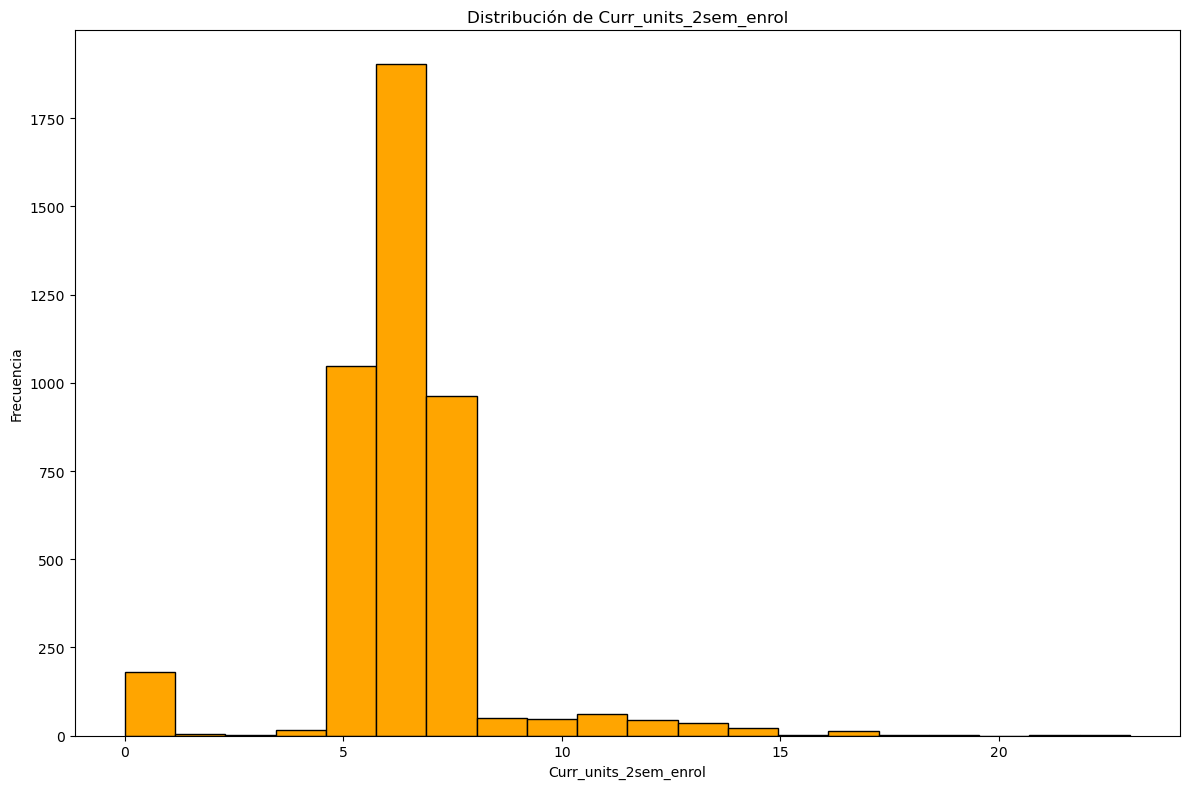

(array([4.020e+02, 6.000e+00, 1.000e+01, 8.960e+02, 1.349e+03, 4.550e+02,
        6.080e+02, 3.510e+02, 9.700e+01, 1.220e+02, 4.700e+01, 1.900e+01,
        1.800e+01, 1.400e+01, 3.000e+00, 4.000e+00, 3.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.  ,  1.65,  3.3 ,  4.95,  6.6 ,  8.25,  9.9 , 11.55, 13.2 ,
        14.85, 16.5 , 18.15, 19.8 , 21.45, 23.1 , 24.75, 26.4 , 28.05,
        29.7 , 31.35, 33.  ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_eval')

Text(0.5, 0, 'Curr_units_2sem_eval')

Text(0, 0.5, 'Frecuencia')

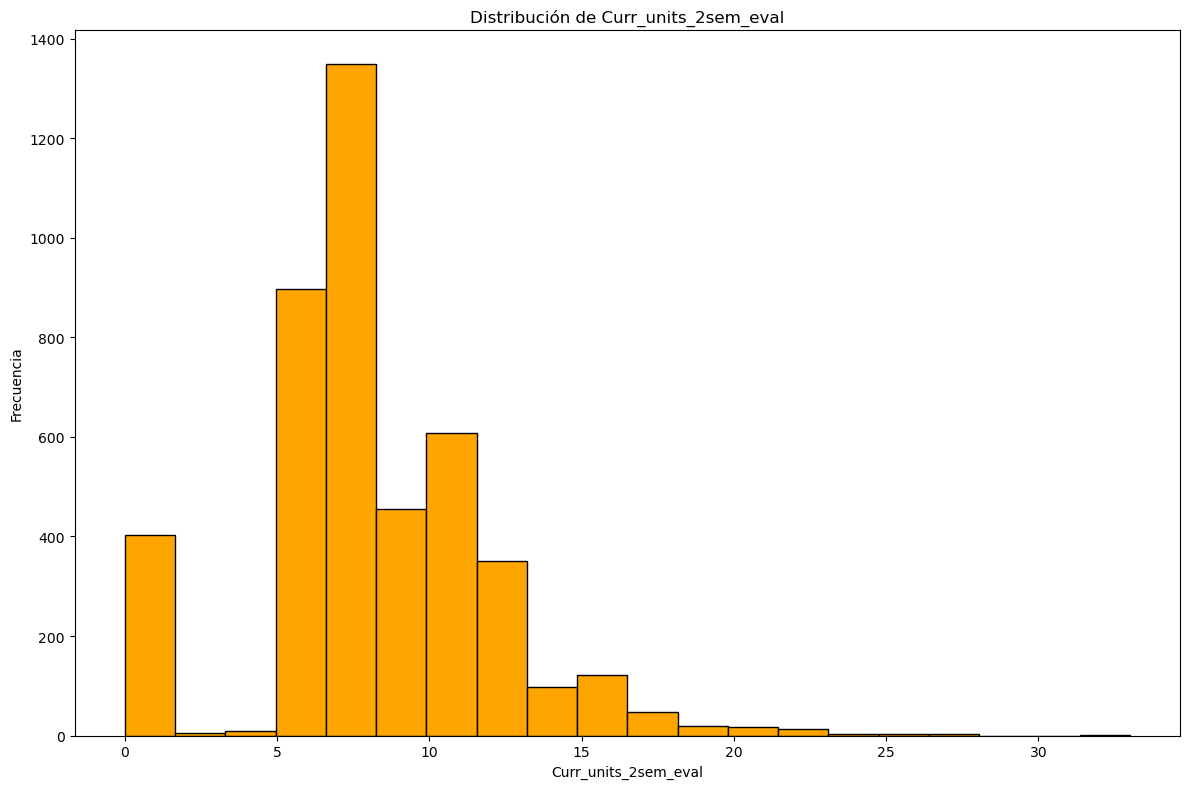

(array([867., 113., 196., 285., 412., 720., 963., 331., 319.,  36.,  37.,
         48.,  34.,  21.,   6.,   0.,   2.,   8.,   2.,   5.]),
 array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
        13., 14., 15., 16., 17., 18., 19., 20.]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_appvd')

Text(0.5, 0, 'Curr_units_2sem_appvd')

Text(0, 0.5, 'Frecuencia')

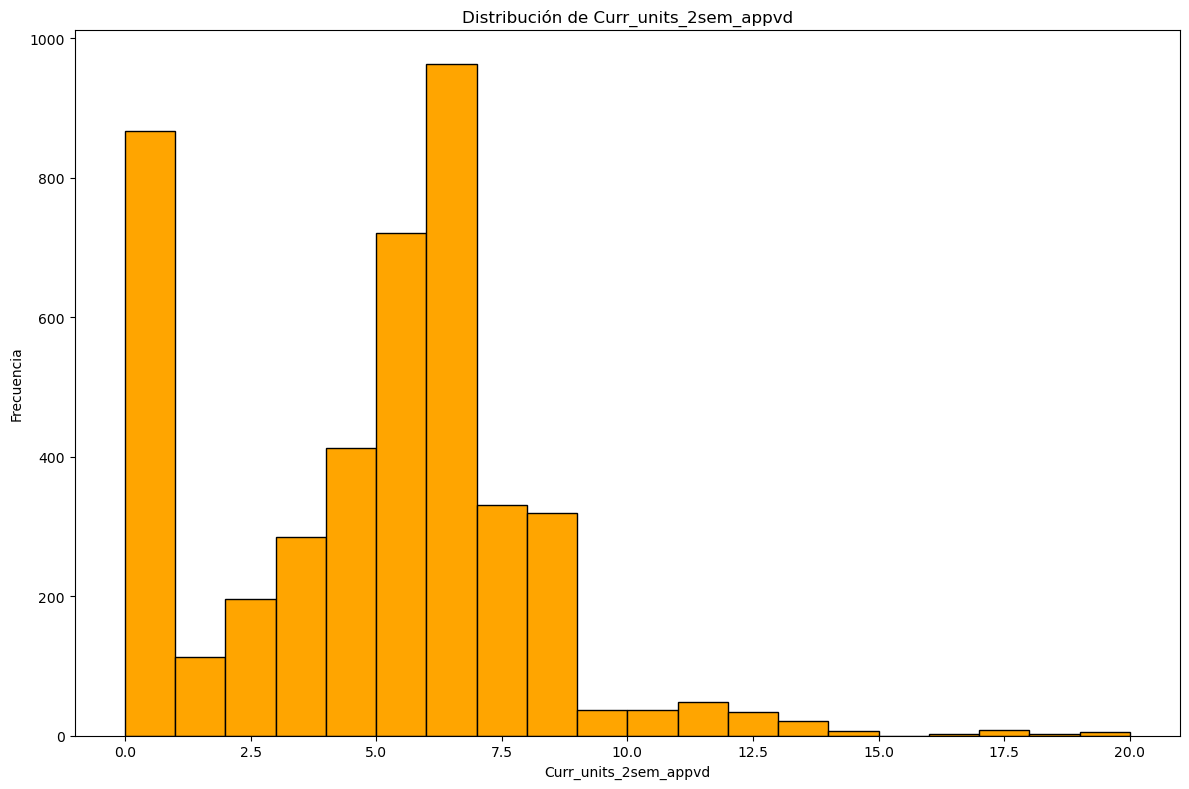

(array([867.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,  83.,
        356., 775., 816., 798., 464., 170.,  63.,  10.,   3.]),
 array([ 0.        ,  0.92857143,  1.85714286,  2.78571429,  3.71428571,
         4.64285714,  5.57142857,  6.5       ,  7.42857143,  8.35714286,
         9.28571429, 10.21428571, 11.14285714, 12.07142857, 13.        ,
        13.92857143, 14.85714286, 15.78571429, 16.71428571, 17.64285714,
        18.57142857]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_grade')

Text(0.5, 0, 'Curr_units_2sem_grade')

Text(0, 0.5, 'Frecuencia')

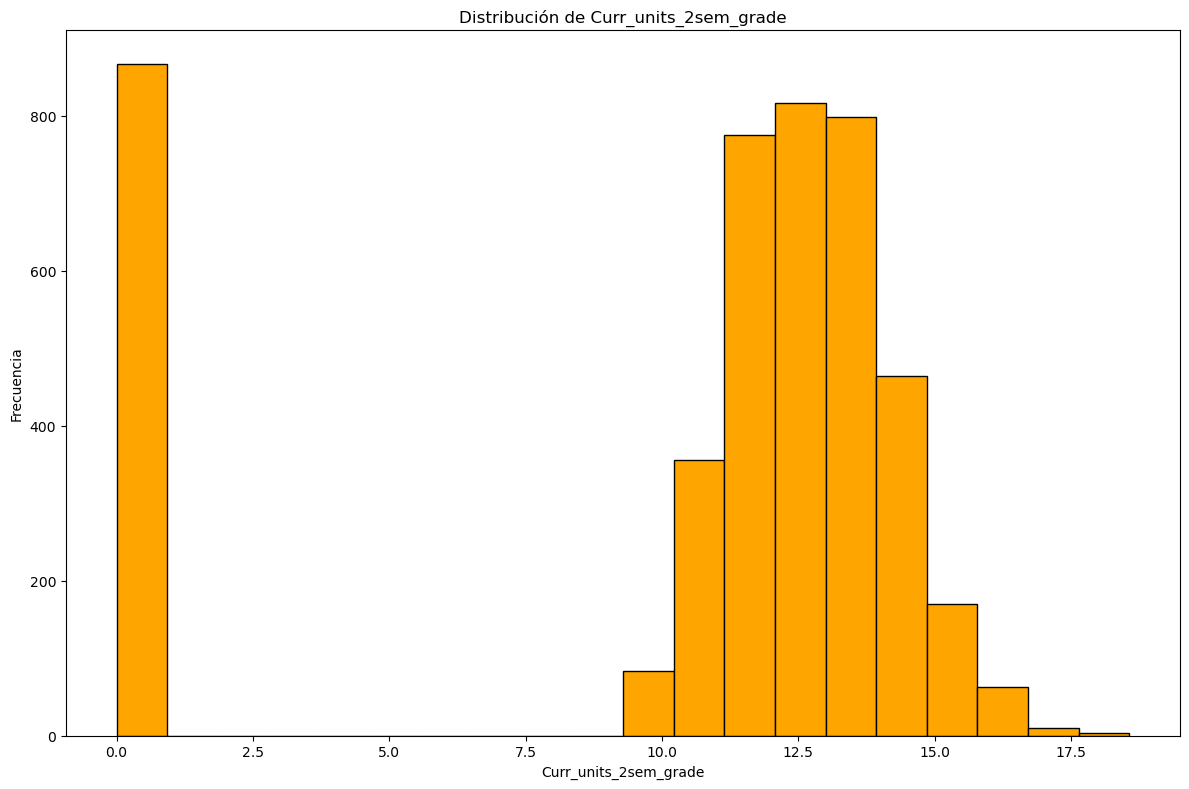

(array([4.124e+03, 1.390e+02, 0.000e+00, 4.800e+01, 0.000e+00, 3.500e+01,
        2.100e+01, 0.000e+00, 1.700e+01, 0.000e+00, 8.000e+00, 5.000e+00,
        0.000e+00, 6.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 2.000e+00]),
 array([ 0. ,  0.6,  1.2,  1.8,  2.4,  3. ,  3.6,  4.2,  4.8,  5.4,  6. ,
         6.6,  7.2,  7.8,  8.4,  9. ,  9.6, 10.2, 10.8, 11.4, 12. ]),
 <BarContainer object of 20 artists>)

Text(0.5, 1.0, 'Distribución de Curr_units_2sem_noevaluat')

Text(0.5, 0, 'Curr_units_2sem_noevaluat')

Text(0, 0.5, 'Frecuencia')

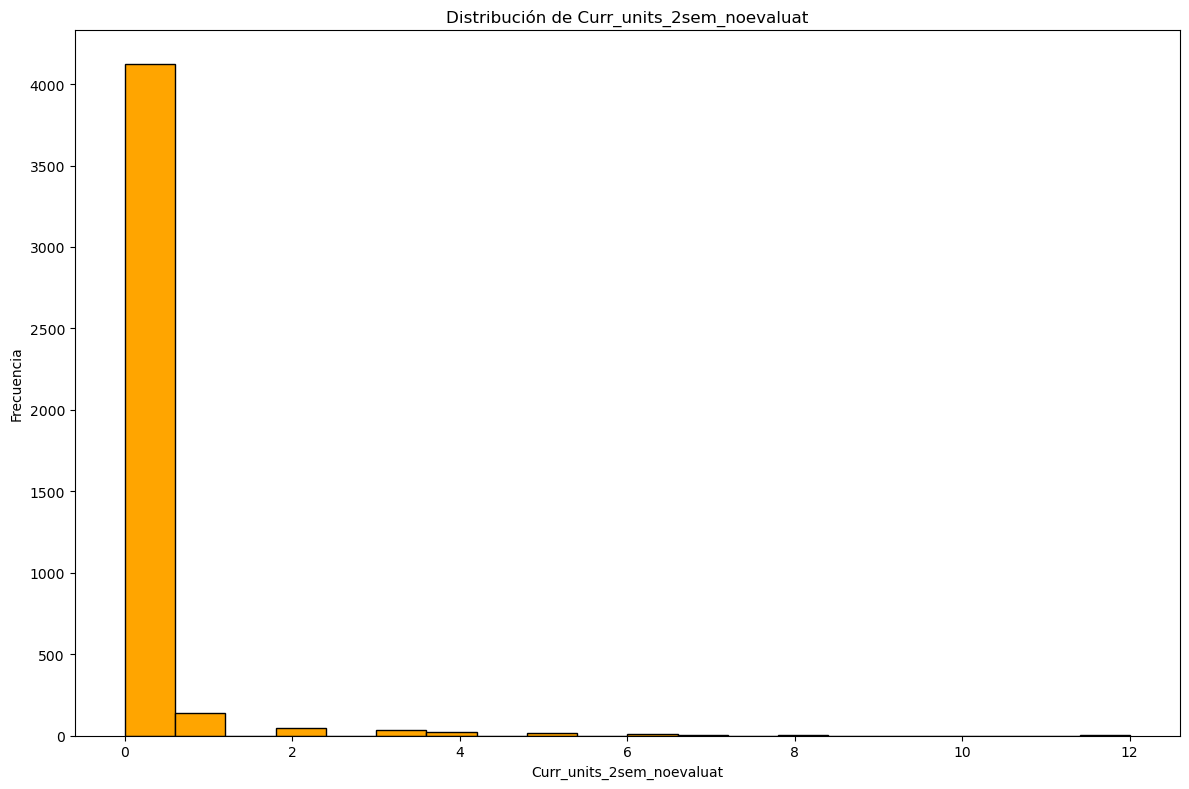

In [30]:
#Integer columns
integ_col = ['Marital_status', 'Appl_mode', 'Appl_order', 'Course', 'Day/evening attend', 'Prev_qualif_grade', 'Nationality',
            "Mother's_qualif", "Father's_qualif", "Mother's_occup", "Father's_occup", 'Displaced', 'Educ_special_needs',
            'Debtor', 'Tuit_fees_upto_date', 'Gender', 'Scholar_holder', 'Age_enrollment', 'Intl', 'Curr_units_1sem_cred',
            'Curr_units_1sem_enrol', 'Curr_units_1sem_eval', 'Curr_units_1sem_appvd', 'Curr_units_1sem_grade',
            'Curr_units_1sem_noeval', 'Curr_units_2sem_cred', 'Curr_units_2sem_enrol', 'Curr_units_2sem_eval',
            'Curr_units_2sem_appvd', 'Curr_units_2sem_grade', 'Curr_units_2sem_noevaluat']

df1[integ_col] = df1[integ_col].apply(pd.to_numeric, errors="coerce")

for i in integ_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Graficar histograma
    ax.hist(df[i].dropna(), bins=20, color='orange', edgecolor='black')
    
    ax.set_title(f'Distribución de {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frecuencia')
    
    plt.tight_layout()
    plt.show()

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Marital_status'>

Text(0.5, 1.0, 'Boxplot of Marital_status')

Text(0.5, 0, 'Marital_status')

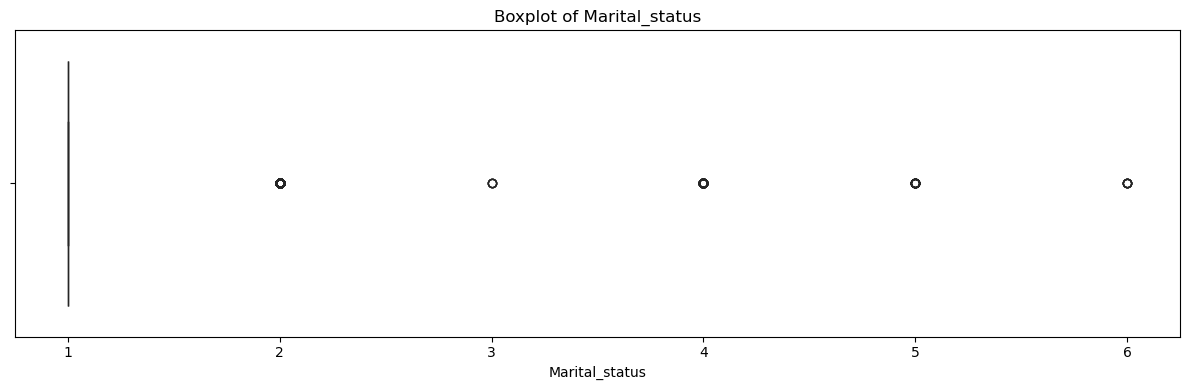

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Appl_mode'>

Text(0.5, 1.0, 'Boxplot of Appl_mode')

Text(0.5, 0, 'Appl_mode')

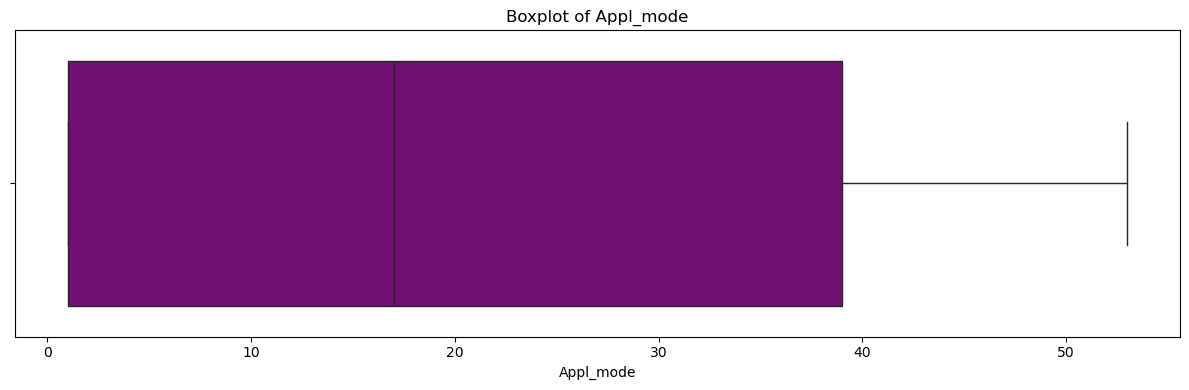

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Appl_order'>

Text(0.5, 1.0, 'Boxplot of Appl_order')

Text(0.5, 0, 'Appl_order')

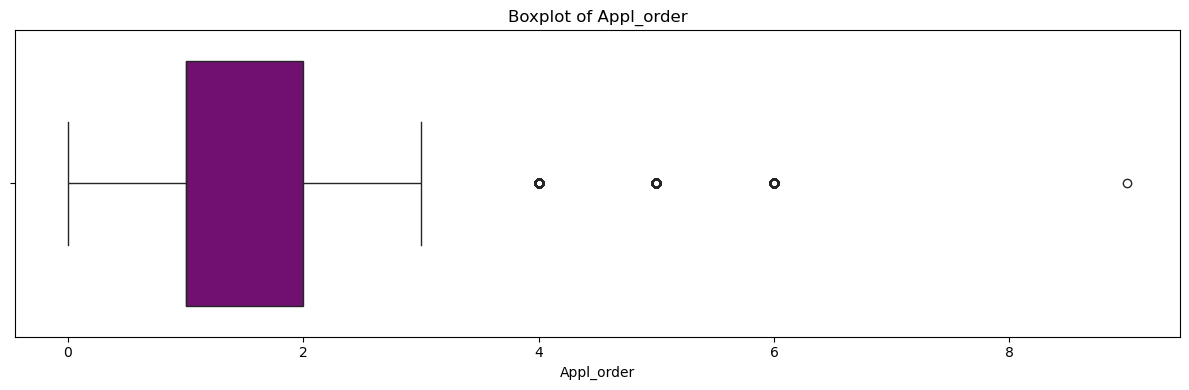

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Course'>

Text(0.5, 1.0, 'Boxplot of Course')

Text(0.5, 0, 'Course')

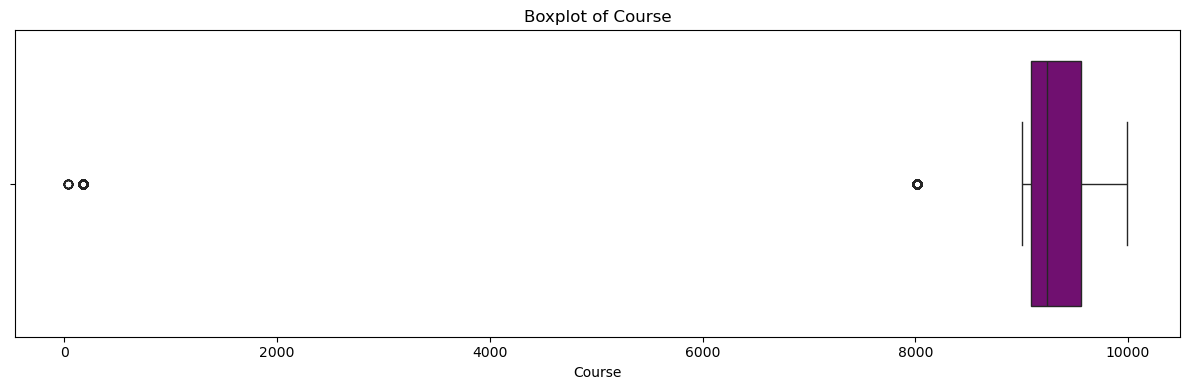

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Day/evening attend'>

Text(0.5, 1.0, 'Boxplot of Day/evening attend')

Text(0.5, 0, 'Day/evening attend')

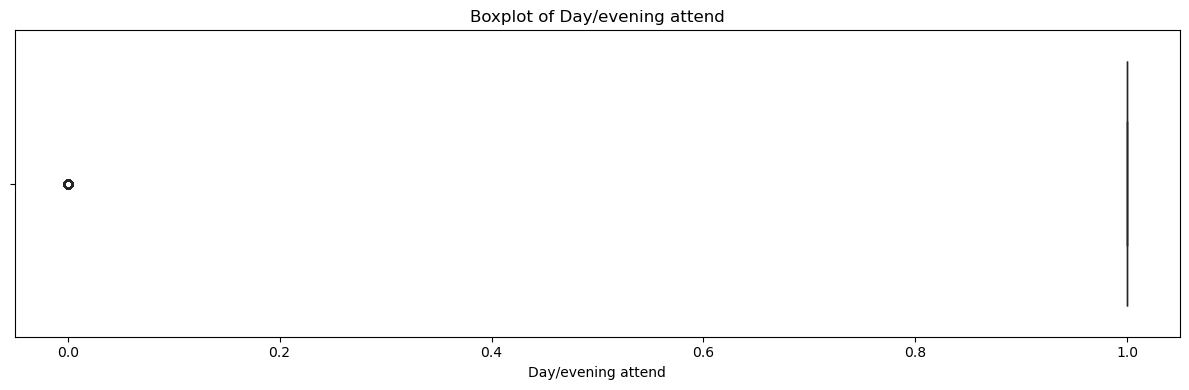

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Prev_qualif_grade'>

Text(0.5, 1.0, 'Boxplot of Prev_qualif_grade')

Text(0.5, 0, 'Prev_qualif_grade')

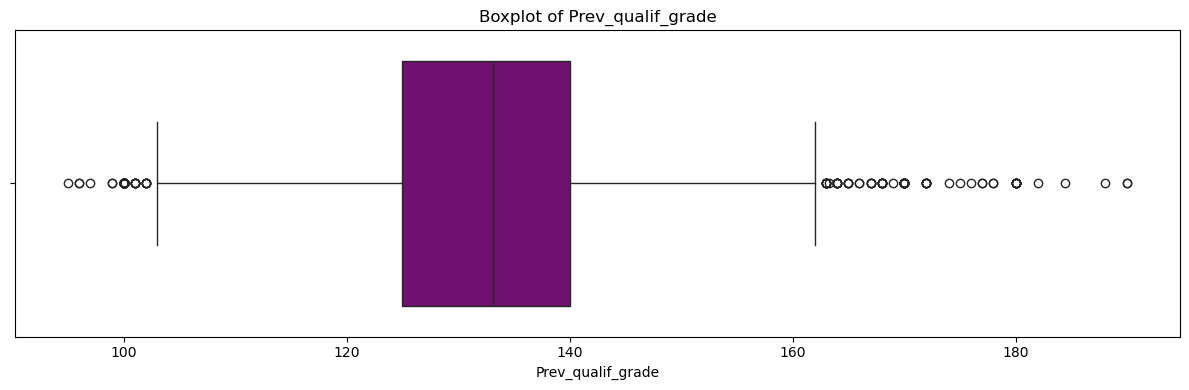

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Nationality'>

Text(0.5, 1.0, 'Boxplot of Nationality')

Text(0.5, 0, 'Nationality')

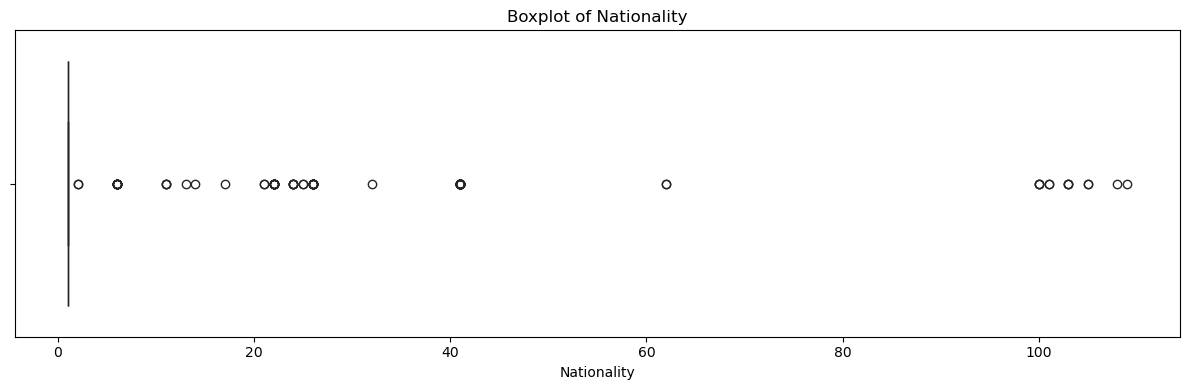

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Mother's_qualif">

Text(0.5, 1.0, "Boxplot of Mother's_qualif")

Text(0.5, 0, "Mother's_qualif")

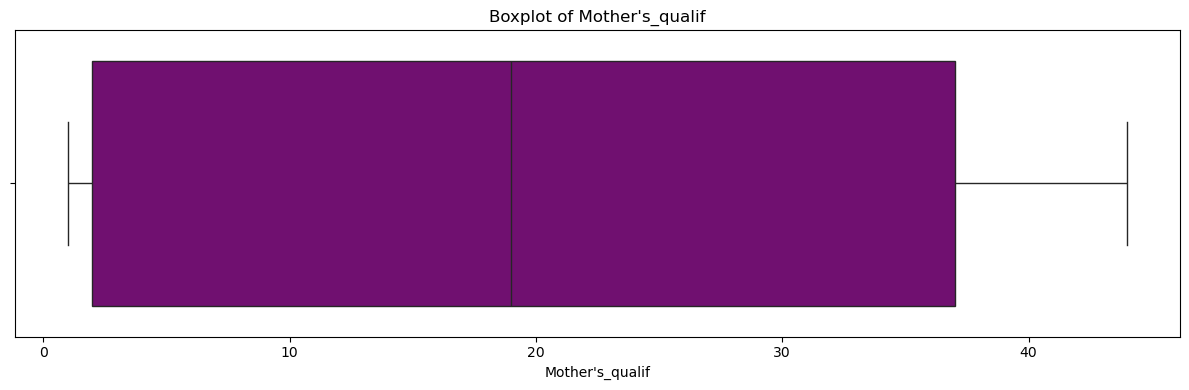

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Father's_qualif">

Text(0.5, 1.0, "Boxplot of Father's_qualif")

Text(0.5, 0, "Father's_qualif")

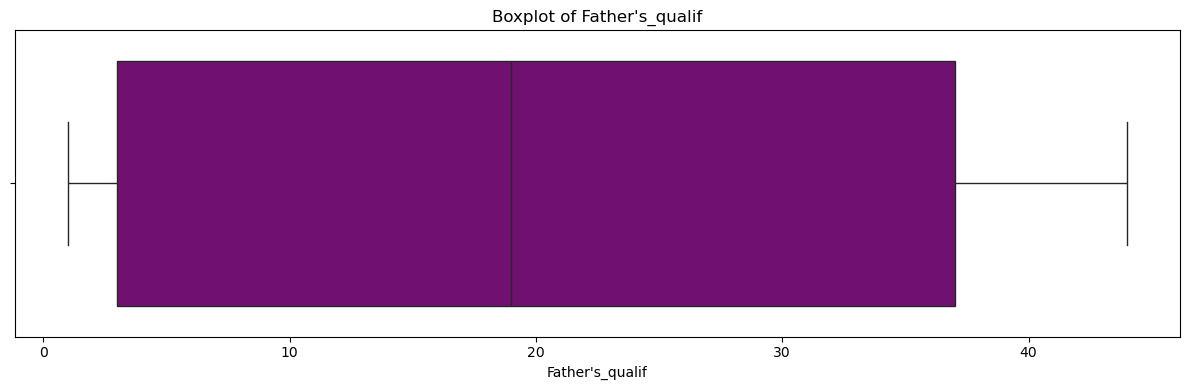

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Mother's_occup">

Text(0.5, 1.0, "Boxplot of Mother's_occup")

Text(0.5, 0, "Mother's_occup")

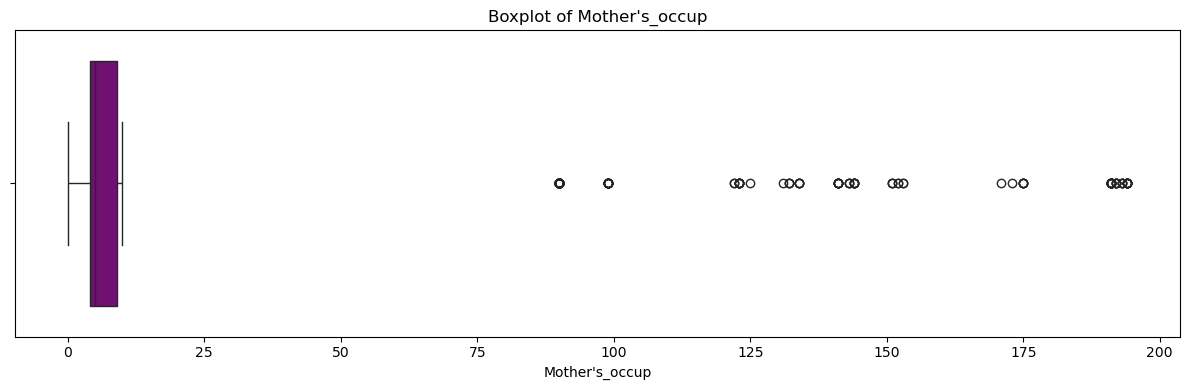

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel="Father's_occup">

Text(0.5, 1.0, "Boxplot of Father's_occup")

Text(0.5, 0, "Father's_occup")

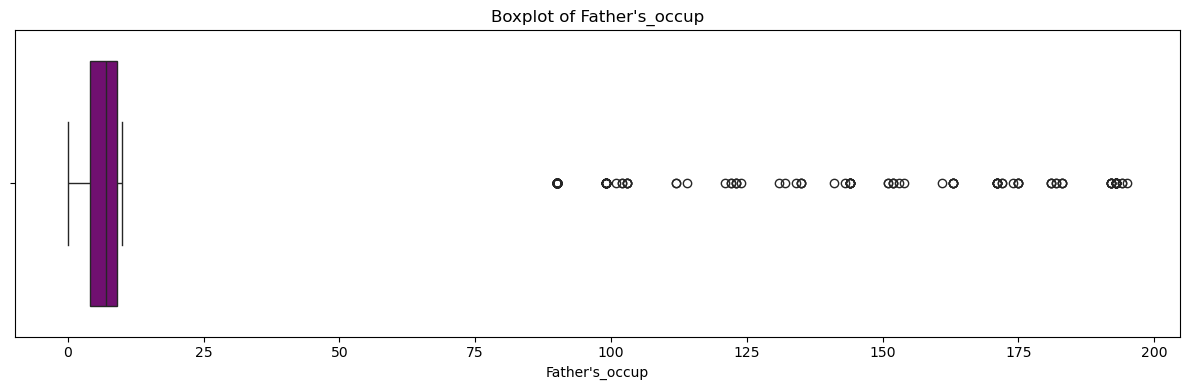

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Displaced'>

Text(0.5, 1.0, 'Boxplot of Displaced')

Text(0.5, 0, 'Displaced')

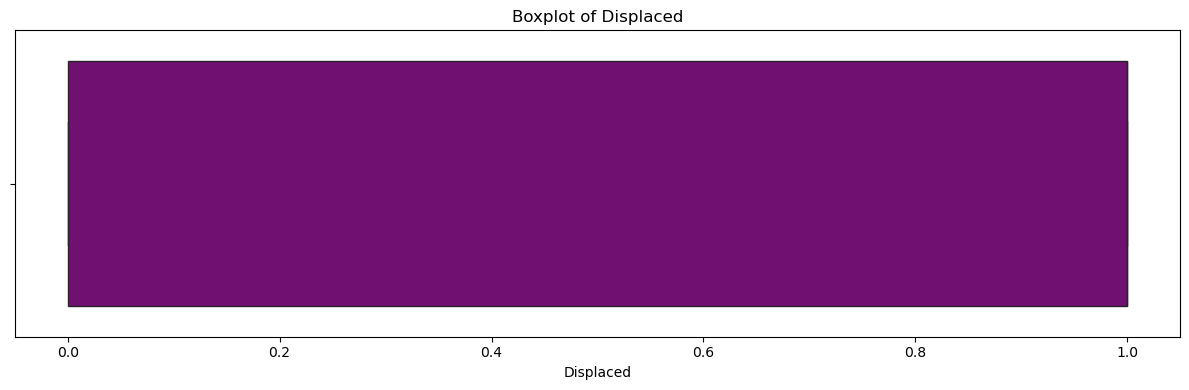

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Educ_special_needs'>

Text(0.5, 1.0, 'Boxplot of Educ_special_needs')

Text(0.5, 0, 'Educ_special_needs')

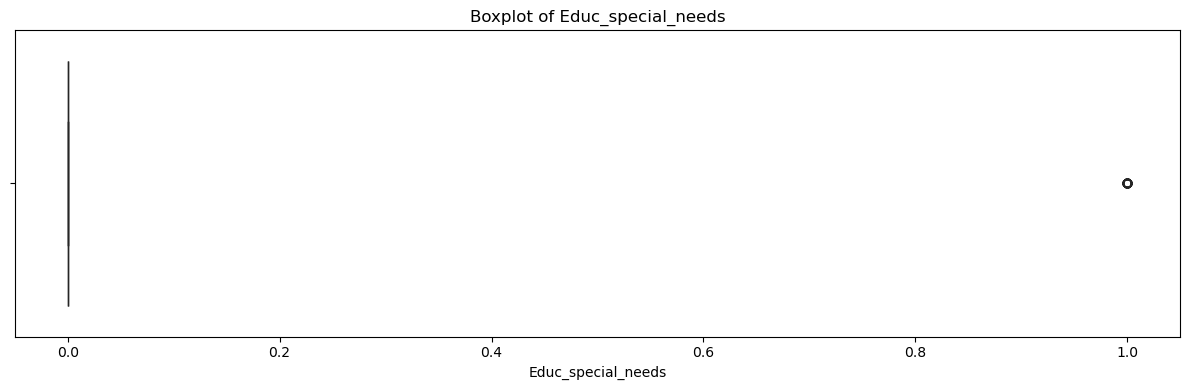

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Debtor'>

Text(0.5, 1.0, 'Boxplot of Debtor')

Text(0.5, 0, 'Debtor')

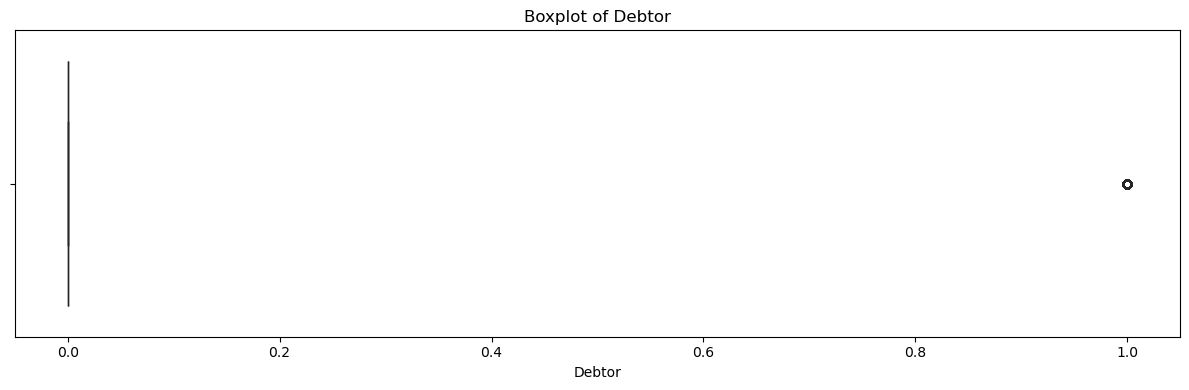

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Tuit_fees_upto_date'>

Text(0.5, 1.0, 'Boxplot of Tuit_fees_upto_date')

Text(0.5, 0, 'Tuit_fees_upto_date')

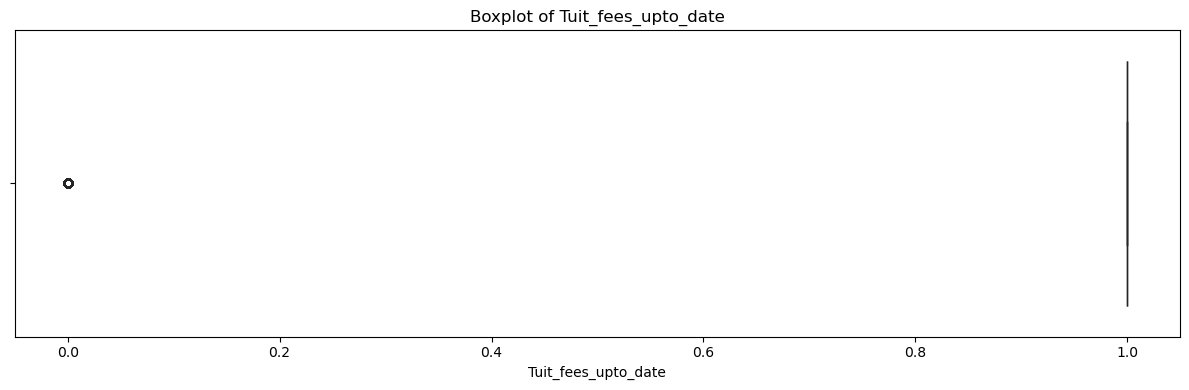

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Gender'>

Text(0.5, 1.0, 'Boxplot of Gender')

Text(0.5, 0, 'Gender')

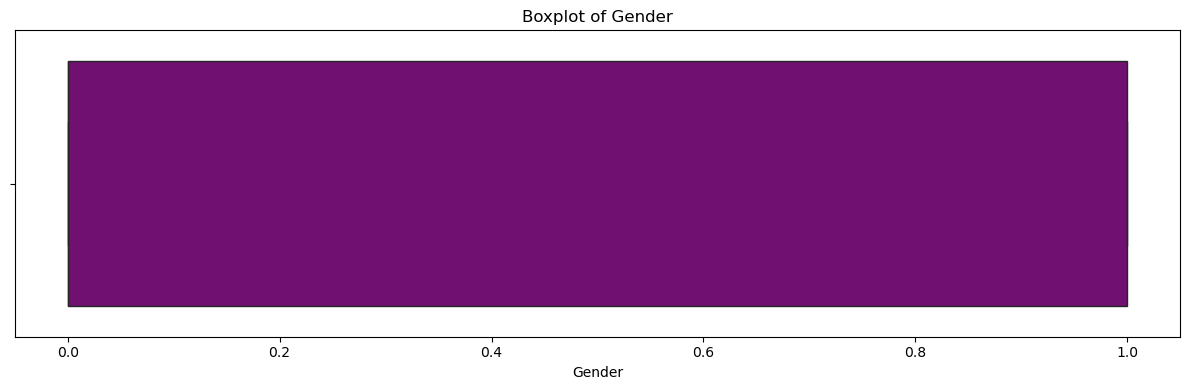

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Scholar_holder'>

Text(0.5, 1.0, 'Boxplot of Scholar_holder')

Text(0.5, 0, 'Scholar_holder')

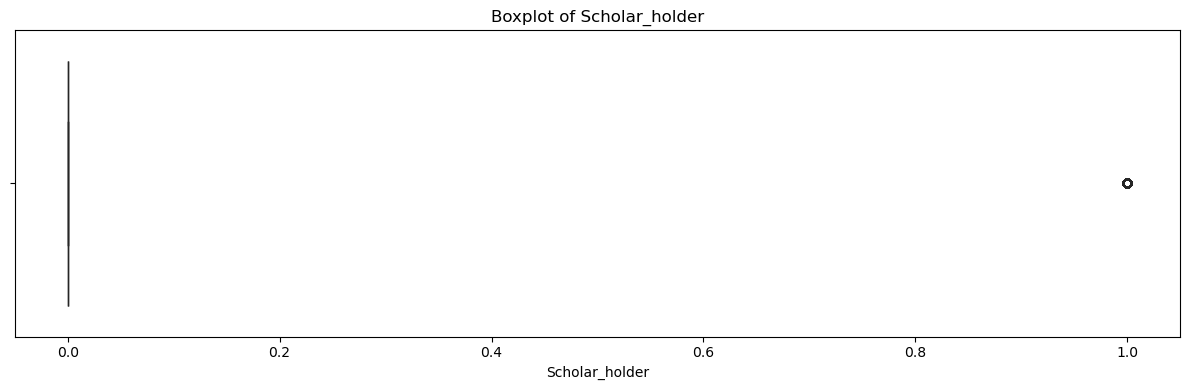

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Age_enrollment'>

Text(0.5, 1.0, 'Boxplot of Age_enrollment')

Text(0.5, 0, 'Age_enrollment')

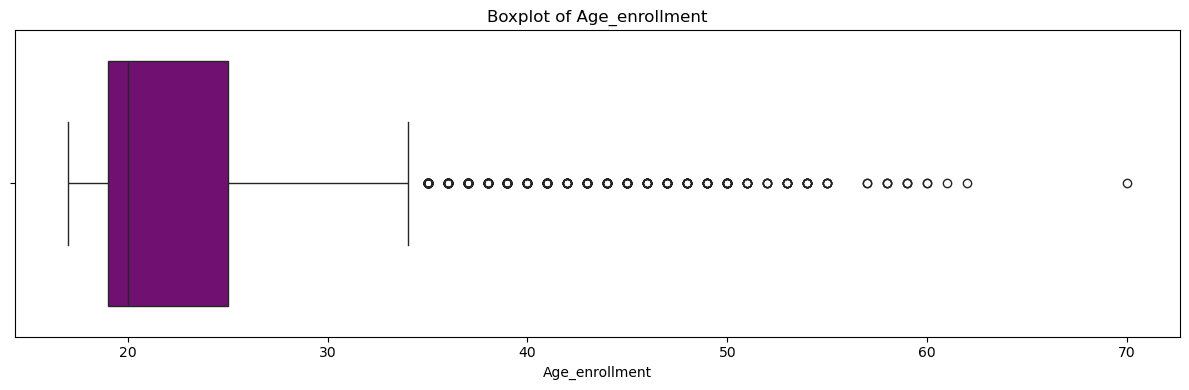

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Intl'>

Text(0.5, 1.0, 'Boxplot of Intl')

Text(0.5, 0, 'Intl')

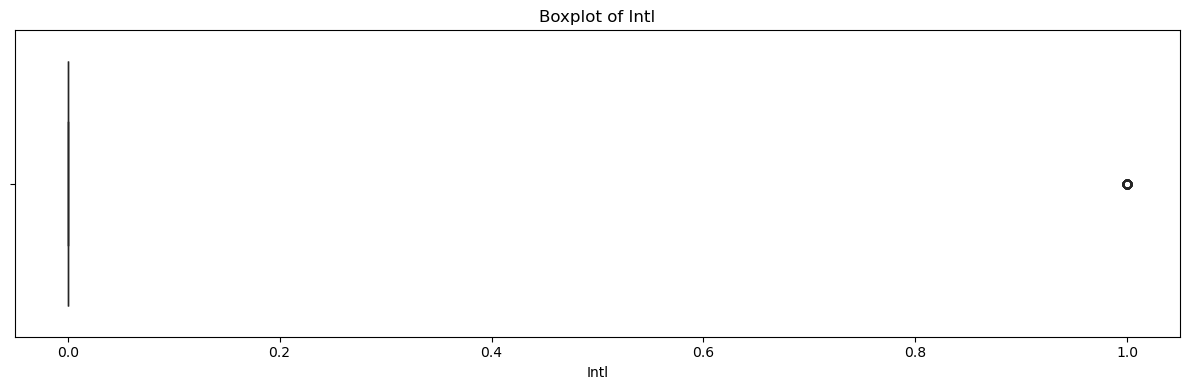

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_cred'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_cred')

Text(0.5, 0, 'Curr_units_1sem_cred')

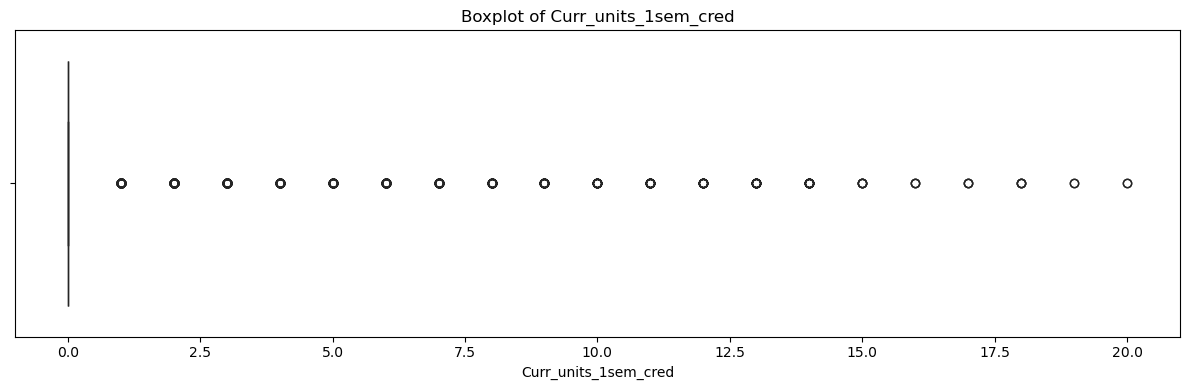

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_enrol'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_enrol')

Text(0.5, 0, 'Curr_units_1sem_enrol')

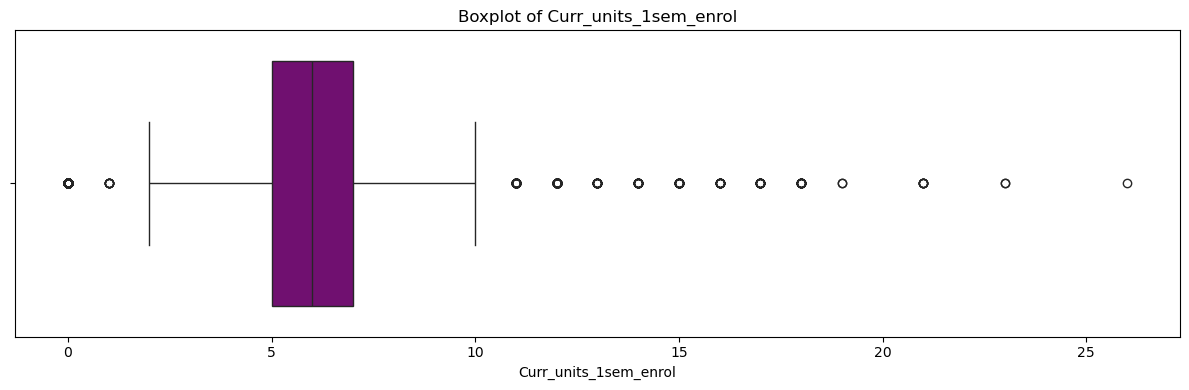

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_eval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_eval')

Text(0.5, 0, 'Curr_units_1sem_eval')

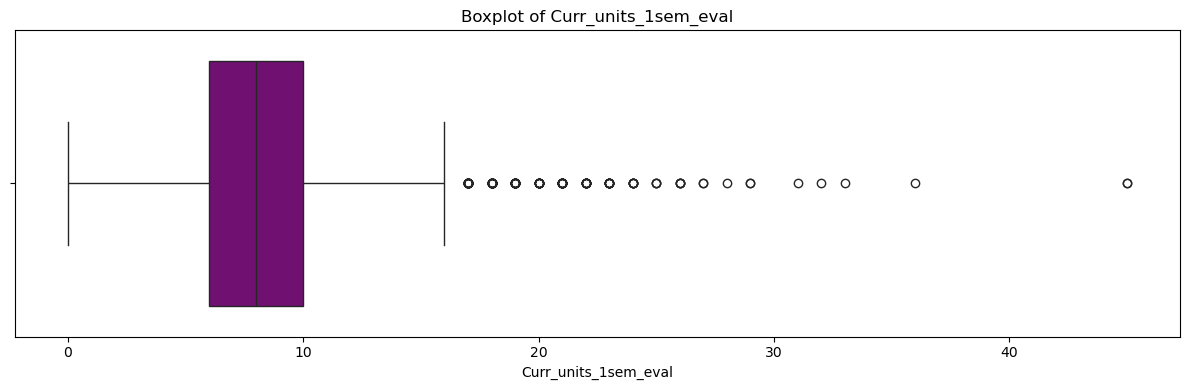

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_appvd'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_appvd')

Text(0.5, 0, 'Curr_units_1sem_appvd')

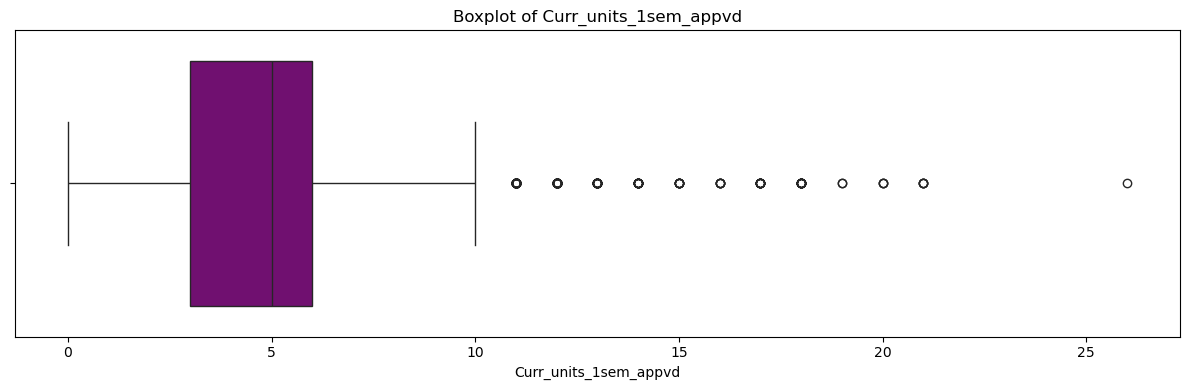

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_grade'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_grade')

Text(0.5, 0, 'Curr_units_1sem_grade')

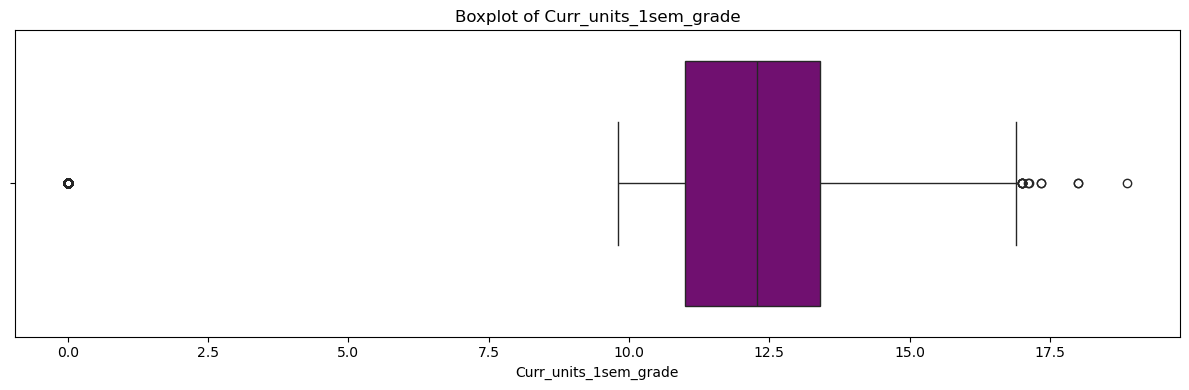

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_1sem_noeval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_1sem_noeval')

Text(0.5, 0, 'Curr_units_1sem_noeval')

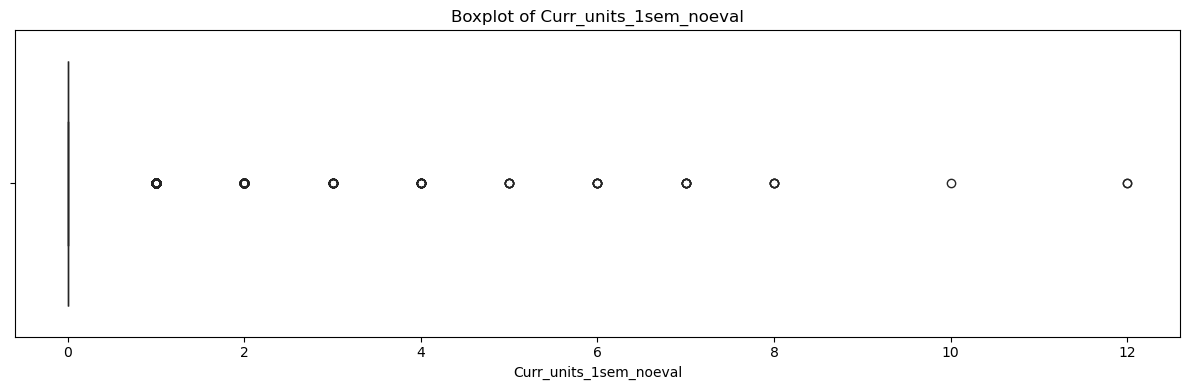

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_cred'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_cred')

Text(0.5, 0, 'Curr_units_2sem_cred')

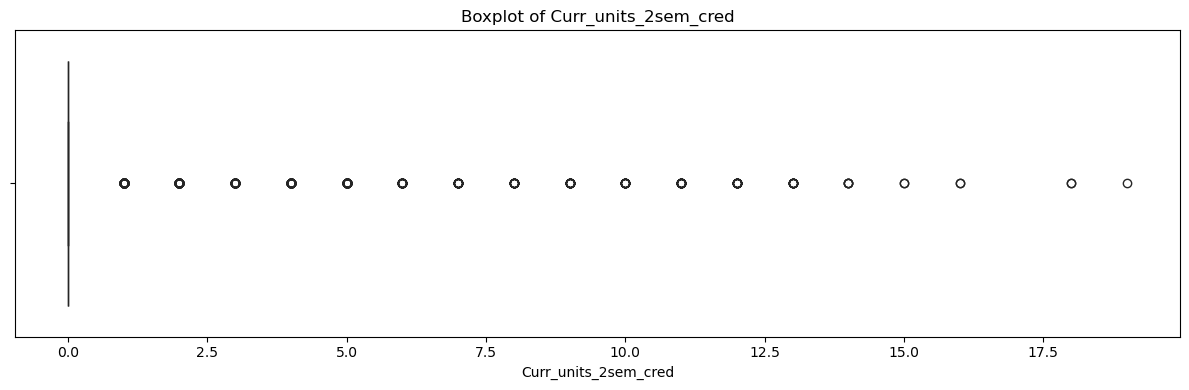

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_enrol'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_enrol')

Text(0.5, 0, 'Curr_units_2sem_enrol')

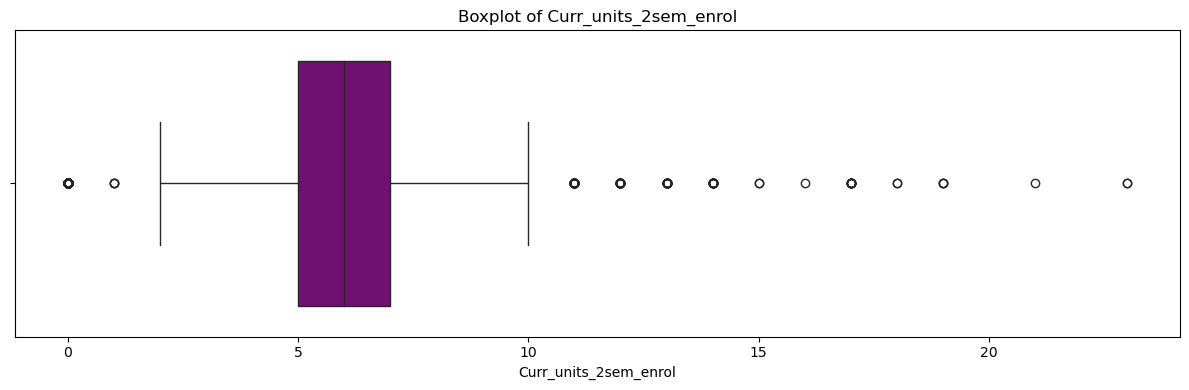

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_eval'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_eval')

Text(0.5, 0, 'Curr_units_2sem_eval')

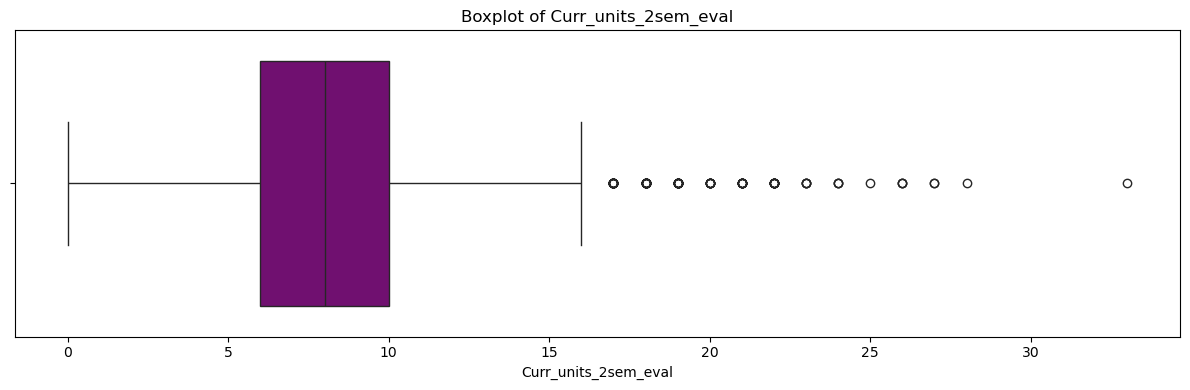

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_appvd'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_appvd')

Text(0.5, 0, 'Curr_units_2sem_appvd')

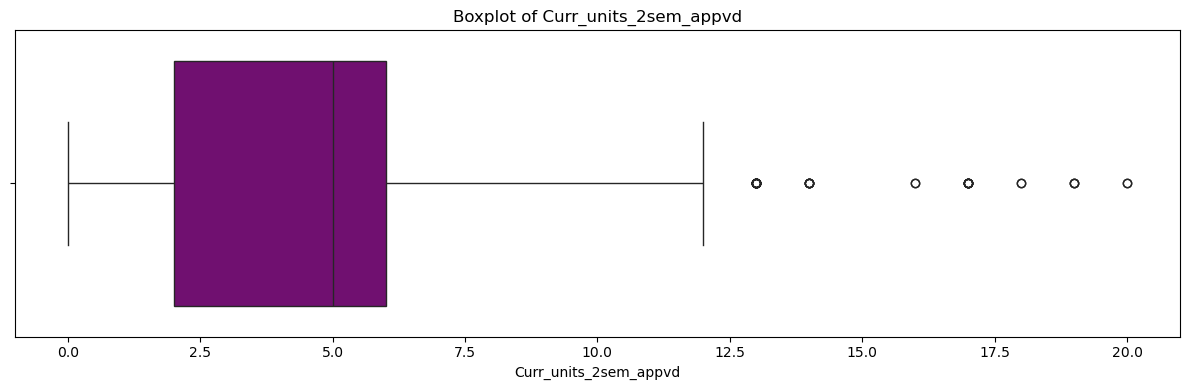

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_grade'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_grade')

Text(0.5, 0, 'Curr_units_2sem_grade')

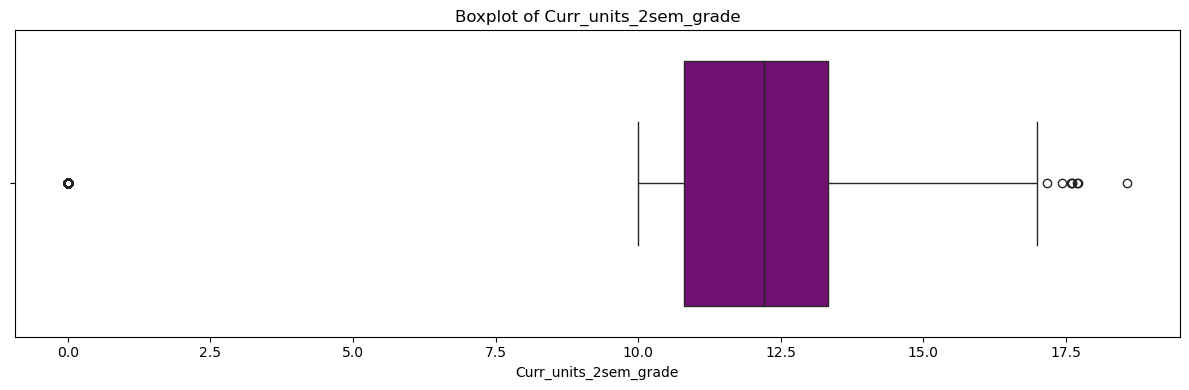

<Figure size 1200x400 with 0 Axes>

<Axes: xlabel='Curr_units_2sem_noevaluat'>

Text(0.5, 1.0, 'Boxplot of Curr_units_2sem_noevaluat')

Text(0.5, 0, 'Curr_units_2sem_noevaluat')

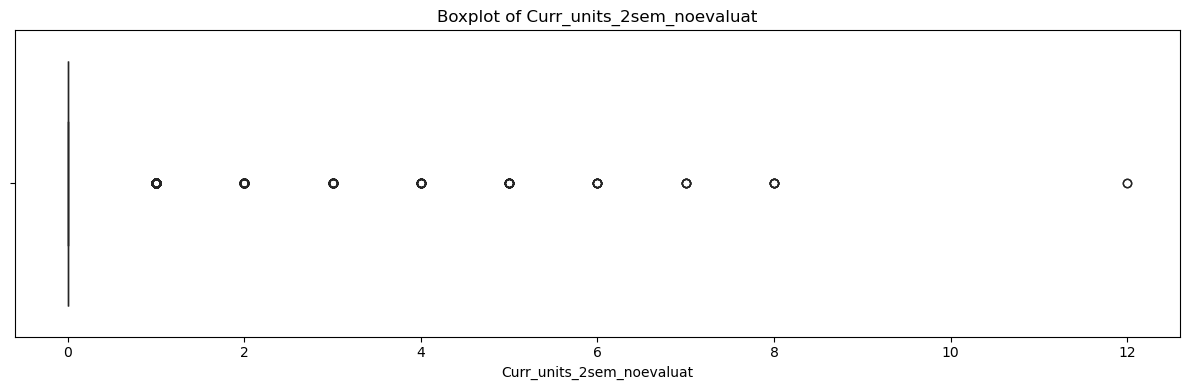

In [31]:
#Boxplot PREGUNTAR A DAVID


for i in integ_col:
    plt.figure(figsize=(12, 4))
    
    # Graficar histograma
    sns.boxplot(x=df1[i].dropna(), color='purple')
    
    plt.title(f'Boxplot of {i}') 
    plt.xlabel(i)
    
    plt.tight_layout()
    plt.show()

In [34]:

df1['Target'] = df1['Target'].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(20,10))
c= df1.corr()
sns.heatmap(c,cmap="BrBG",annot=True)
c

ValueError: Columns must be same length as key